# 타이타닉 승객 유형으로 생존 가능성을 설명할 수 있는가

**작성자:** 복헌영 &nbsp;&nbsp;|&nbsp;&nbsp; **작성일:** 2026-10-09 

## #1. 분석 개요

**분석 주제**

> Kaggle 공개 데이터인 Titanic Dataset(`train.csv`, 891명)으로 **어떤 유형의 승객이 생존 가능성이 더 높은지** 확인한다.
> 실제 이해관계자가 있는 과제가 아니라, 로지스틱 회귀의 전 과정(품질 점검 → 파생변수 → EDA → 최종 변수 채택)을 연습하기 위한 분석이다.

**분석 질문**

- **Q1.** 승객의 생존 여부를 가르는 주요 요인은 무엇인가?
- **Q2.** 어느 유형의 승객 집단이 더 높은 생존 가능성을 보이는가?

**종속변수:** `Survived` (명목형, 생존 여부 / 0=사망, 1=생존) → **이진 분류 문제(로지스틱 회귀)**

**이번 노트북에서 연습할 기법**

> 컬럼 성격에 따른 **결측치 대체(중앙값·최빈값)**, 이름에서 **호칭 파생변수(`Title`)** 와 **가족 수 파생변수(`FamilySize`)** 생성,
> 정규성 위배 시 **Mann-Whitney U 검정**, **카이제곱 독립성 검정과 Cramer's V**, **VIF 기반 다중공선성 점검**,
> 그리고 **서열척도 선언과 더미변수 기준 범주 지정**을 연습한다.

### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**

In [1]:
import sys
sys.path.append("D:\\") 
from helpers import *
from IPython.display import display, Markdown

## 노트북에서 직접 호출하지는 않지만, 분석 환경(버전) 확인용으로 함께 참조한다.
import pandas as pd
import numpy as np
import statsmodels.api as sm
from pandas import DataFrame, crosstab

---
## #2. 데이터 소개

### 2-1. 데이터 불러오기

In [2]:
origin = pd.read_csv('train.csv')
display(origin.head())
display(origin.tail())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


### 2-2. 출처와 분석 단위

- **출처:** Titanic - Machine Learning from Disaster — Kaggle 공식 데이터셋 [Titanic Dataset](https://www.kaggle.com/competitions/titanic/data)
- **수집 기간:** 1912년 4월 15일 타이타닉호 침몰 사건을 기반으로 한 역사적 승객 기록
- **분석 단위:** 1행 = 타이타닉호 승객 1명
- **데이터 규모:** 891행 × 12열 (train.csv 기준)
- **분석 목적:** 승객의 성별, 나이, 객실 등급, 요금 등의 정보를 활용하여 생존 여부를 분석하고 예측
- **종속변수:** Survived (0=사망, 1=생존)

> ⚠️ Kaggle이 제공한 test 데이터는 정답 라벨이 공개되지 않아 사용하지 않았다.<br/>정답이 있는 train 데이터 891건을 직접 훈련/검증으로 분할해 로지스틱 회귀와 SHAP 분석을 수행했다.

### 2-3. 변수 정의서

| 변수명 | 의미 | 역할 | 척도 | 값 / 단위 |
|---|---|---|---|---|
| PassengerId | 탑승객 식별자 | 식별자 | 명목형 | 승객 고유번호 |
| Survived | 생존 여부 | 종속변수 | 명목형(2집단) | 0=사망, 1=생존 |
| Pclass | 객실 등급 | 독립변수 | 순서형 | 1=1등급, 2=2등급, 3=3등급 |
| Name | 이름 | 독립변수 | 명목형 | 승객 이름 |
| Sex | 성별 | 독립변수 | 명목형 | male=남성, female=여성 |
| Age | 나이 | 독립변수 | 연속형 | 세(년) |
| SibSp | 동승한 형제·배우자 수 | 독립변수 | 이산형 | 명 |
| Parch | 동승한 부모·자녀 수 | 독립변수 | 이산형 | 명 |
| Ticket | 티켓 번호 | 독립변수 | 명목형 | 티켓 식별번호 |
| Fare | 요금 | 독립변수 | 연속형 | 파운드(£) |
| Cabin | 선실 번호 | 독립변수 | 명목형 | 객실 번호 |
| Embarked | 탑승 항구 | 독립변수 | 명목형 | C=Cherbourg, Q=Queenstown, S=Southampton |

### 2-4. 컬럼 의미를 정리한 딕셔너리

In [3]:
column_means = {
    "PassengerId": "탑승객 식별자",
    "Survived":    "생존 여부 (0=사망, 1=생존)",
    "Pclass":      "객실 등급 (1=1등급, 2=2등급, 3=3등급)",
    "Name":        "이름",
    "Sex":         "성별",
    "Age":         "나이",
    "SibSp":       "동승한 형제·배우자 수",
    "Parch":       "동승한 부모·자녀 수",
    "Ticket":      "티켓 번호",
    "Fare":        "요금",
    "Cabin":       "선실 번호",
    "Embarked":    "탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)",
}

### 2-5. 초기 가설

- **H1.** 남성 승객의 생존율은 여성 승객보다 낮을 것이다.
- **H2.** 상위 객실 등급(1등급 > 2등급 > 3등급)의 승객일수록 생존율이 높을 것이다.
- **H3.** 가족과 동승한 승객(SibSp + Parch ≥ 1)의 생존율은 단독 승객보다 높을 것이다. 
- **H4.** 어린이(12세 이하) 승객의 생존율은 성인 승객보다 높을 것이다.

### 2-6. 데이터의 한계

- **시점:** 1912년 4월 15일 타이타닉호 침몰 사건을 기반으로 한 **과거의 횡단면 데이터**다. 당시 승객의 생존 여부를 예측하는 데는 활용할 수 있지만, 단일 사건의 기록이므로 학습한 모형을 다른 시기나 현대 해상 사고에 그대로 적용하기는 어렵다.

- **관측 단위와 표본:** **개별 승객 1명**을 기준으로 구성된 데이터다. 실제 탑승 인원은 약 2,224명이지만 이 데이터는 **승무원을 제외한 승객 중 891명**만 포함하며, Kaggle은 학습/평가 데이터의 분할 방식을 밝히지 않았다. 따라서 표본이 전체 탑승객을 대표한다고 보기 어렵다.

- **평가 데이터의 부재:** Kaggle의 `test.csv`에는 정답(`Survived`)이 없으므로, 이 노트북은 **`train.csv`만 사용**한다. 모형의 성능은 891명을 다시 학습용과 검증용으로 나누거나 교차검증으로 평가해야 한다.

- **클래스 불균형:** 생존자는 **342명(38.4%)** 으로 사망자보다 적다. 모든 승객을 '사망'으로 예측해도 정확도가 61.6%가 나오므로, **정확도만으로는 모형 성능을 충분히 판단하기 어렵다.**

- **결측치 문제:** `Age`(177건, 19.9%), `Cabin`(687건, 77.1%), `Embarked`(2건)에 **결측치(NaN)** 가 있다. `Age` 결측은 3등급에 몰려 있고, 결측인 승객의 생존율(29.4%)은 나이가 기록된 승객(40.6%)보다 낮아 **무작위 결측으로 보기 어렵다.** 결측 처리 방법에 따라 분석 결과가 달라질 수 있다.

- **측정의 한계:** `Fare`에는 0인 값이 15건 있고, 단체 티켓은 1인 요금이 아닌 총액으로 기록되어 있다. `SibSp`·`Parch`는 친척만 집계하므로 친구, 하인, 유모 같은 동행자는 반영하지 못한다.

- **변수의 한계:** 침몰 당시의 위치, 구명보트까지의 거리, 국적과 언어 등 생존에 영향을 미쳤을 수 있는 정보가 포함되어 있지 않다. 따라서 성별, 나이, 객실 등급과 생존 여부의 관계는 **연관성**일 뿐이며 인과관계로 단정할 수 없다.

- **윤리적 문제:** `Sex`, `Age`, `Pclass` 등 성별·나이·사회경제적 지위와 관련된 변수가 포함되어 있다. 이러한 변수에 따른 생존율 차이를 분석할 수 있지만, 특정 집단에 대한 차별이나 편견을 정당화하는 근거로 사용해서는 안 된다.
  - 이 노트북에서는 **기법 학습 목적**으로만 데이터를 사용하며, 분석 결과를 특정 집단에 대한 가치 판단의 근거로 삼지 않는다.

---
## #3. 데이터 품질 점검

> 이 장에서는 **불필요한 컬럼 삭제와 결측치 대체**를 수행한다.
> 로지스틱 회귀는 결측치가 하나라도 있으면 적합되지 않으므로, EDA에 들어가기 전에 결측을 모두 처리한다.
<br/> 이상치는 **삭제하지 않는다.** (근거는 '#5-2'에서 정리)

### 3-1. 자료형 확인

In [4]:
origin.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


### 3-2 데이터 중복 점검

In [5]:
df0 = my_qtcheck.check_duplicates(origin, drop=True)

중복된 행의 수: 0


### 3-3. 불필요한 컬럼 제거와 자료형 변환

| 컬럼 | 제거 이유 |
|---|---|
| `PassengerId` | **행마다 값이 모두 다른 식별자**다. 숫자로 저장되어 있어 그대로 두면 연속형 독립변수로 잘못 투입된다. |
| `Name` | 891개가 모두 다른 **자유 텍스트**다. 그대로는 변수가 될 수 없다. (호칭은 #4에서 `origin`으로부터 따로 추출한다) |
| `Ticket` | 형식이 제각각인 **문자열 식별자**다. (`A/5 21171`, `113803`, `STON/O2. 3101282` …) |
| `Cabin` | **결측이 687건(77.1%)** 이다. 채울 근거가 없는 수준이므로 컬럼째 제거한다. |


- 남은 컬럼 중 `Survived`·`Pclass`·`Sex`·`Embarked`를 **명목형(category)** 으로 변환한다.
  - `Survived`는 종속변수이고, `Pclass`는 1·2·3이라는 숫자로 저장되어 있지만 **"3등급은 1등급의 3배"가 아니므로** 연속형으로 두면 안 된다.

In [6]:
# 원본에서 제거된 중복 데이터가 없으므로 계속 원본 사용
df0 = origin.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"]) # 불필요한 컬럼 제거
df1 = my_qtcheck.set_type(df0, as_category=["Survived", "Pclass", "Sex", "Embarked"]) # 명목형으로 변환

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Survived  891 non-null    category
 1   Pclass    891 non-null    category
 2   Sex       891 non-null    category
 3   Age       714 non-null    float64 
 4   SibSp     891 non-null    int64   
 5   Parch     891 non-null    int64   
 6   Fare      891 non-null    float64 
 7   Embarked  889 non-null    category
dtypes: category(4), float64(2), int64(2)
memory usage: 31.5 KB


**해석**

- **자료형:** `Survived`, `Pclass`, `Sex`, `Embarked` 컬럼을 명목형으로 변환하였다.
- **중복 행:** **0건** — 삭제 대상이 없다.
- **불필요한 열:** `info()` 로 확인한 12개 열 중 `PassengerId`, `Name`, `Ticket`, `Cabin` 4개의 열을 삭제하였다.
- **주의할 변수:**
  - `Age`: 891건 중 **177건(19.9%)이 결측**이다. 결측이 3등급에 몰려 있어 무작위 결측으로 보기 어렵고, 처리 방법(삭제·대체)에 따라 결과가 달라질 수 있다. 추정치(xx.5 형태)도 섞여 있다.
  - `Embarked`: **2건이 결측**이다. 건수가 적어 최빈값(S)으로 대체하거나 행을 삭제해도 영향은 작다.
  - `Fare`: 결측은 없지만 **0인 값이 15건** 있고, 최댓값(512.33)이 매우 커서 **오른쪽으로 크게 치우친 분포**다. 단체 티켓은 총액으로 기록되어 있으며, `Pclass`와 상관이 높아 **다중공선성**을 확인해야 한다.
  - `Pclass`: 명목형으로 변환했지만 실제로는 **순서형**(1등급이 최상위)이다. 회귀 모형에는 더미 변수로 넣고 기준 범주를 정해야 한다.
  - `SibSp`, `Parch`: 대부분 0이고 일부만 큰 값(최대 8, 6)을 가지는 **치우친 이산형 변수**다. 두 변수는 의미가 겹치므로 `FamilySize` 등 파생변수로 합칠지 검토가 필요하다.
  - `Survived`: 종속변수로, 생존자가 **342명(38.4%)** 인 **불균형 이분형 변수**다. 모형 학습 시에는 category가 아닌 **정수형(0/1)** 이 필요할 수 있다.

### 3-4. 결측치 점검

In [7]:
my_qtcheck.check_missing_values(df1)

,Missing Count,Missing Ratio (%)
Survived,0,0.000000
Pclass,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Fare,0,0.000000
Embarked,2,0.224467


**해석**

- **결측 컬럼은 2개뿐이다.** `Age` 177건(19.9%), `Embarked` 2건(0.2%). 나머지 6개 컬럼은 결측이 없다.
- **`Age`의 결측은 무시할 수 없는 규모다.** 다섯 명 중 한 명꼴이라 행을 삭제하면 891행이 714행으로 줄어든다.
  - 결측이 3등급에 몰려 있으므로(177건 중 136건), 삭제하면 **3등급 승객이 덜 반영된 표본**이 된다.
  - → 삭제 대신 **대체**한다.
- **`Embarked` 2건은 영향이 거의 없다.** 삭제해도 되지만, 행 수를 유지하기 위해 최빈값으로 대체한다.

### 3-5. 결측치 처리 - **대체**

- 로지스틱 회귀는 결측치가 하나라도 있으면 적합되지 않는다. **모델링 전에 반드시 채워야 한다.**
- 컬럼의 성격에 따라 대체 방법을 다르게 쓴다.

| 컬럼 | 결측 | 대체 방법 | 이유 |
|---|---|---|---|
| `Age` | 177건 (19.9%) | **중앙값** | 오른쪽 꼬리가 있는 분포라 평균은 극단값에 끌려간다 |
| `Embarked` | 2건 (0.2%) | **최빈값** | 명목형이므로 평균·중앙값을 쓸 수 없다 |

- ⚠️ `Age`의 결측치를 하나의 값으로 채우는 것은 **가볍게 볼 일이 아니다.**
  나이 분포에 중앙값 자리의 인공적인 봉우리가 생기고, 나이의 효과가 **실제보다 약하게** 추정된다.
  <br/>이 한계는 반드시 기록해 두어야 한다.

In [8]:
df2 = my_prep.replace_missing(df1, columns=["Age"], method="median")
df3 = my_prep.replace_missing(df2, columns=["Embarked"], method="mode")

# 결측치가 모두 처리되었는지 확인
my_qtcheck.check_missing_values(df3)

결측치 처리 방식: 'median'
컬럼                     결측치                 대체값
--------------------------------------------
Age          177개(19.9%)              28.0
결측치 처리 방식: 'mode'
컬럼                     결측치                 대체값
--------------------------------------------
Embarked        2개(0.2%)                 S


,Missing Count,Missing Ratio (%)
Survived,0,0.0
Pclass,0,0.0
Sex,0,0.0
Age,0,0.0
SibSp,0,0.0
Parch,0,0.0
Fare,0,0.0
Embarked,0,0.0


**해석** — 결측치 ( 0 )건 삭제, ( 179 )건 대체. 관측치 ( 891 ) → ( 891 ).

- **`Age` 177건을 중앙값 28.0세로 대체했다.** 평균(29.7세)보다 극단값의 영향을 덜 받는 중앙값을 택했다.
- **`Embarked` 2건을 최빈값 `S`로 대체했다.** `S`는 전체의 72%를 차지하는 항구라 분포에 주는 영향이 거의 없다.
- ⚠️ **대체의 부작용:** `Age = 28`인 승객이 원래 25명에서 **202명**으로 늘었다. #7-3의 히스토그램에서 28세 자리에 **인공적인 봉우리**로 나타난다.
  - 더 나은 대안은 **호칭(`Title`)별 중앙값으로 대체**하는 것이다. 예컨대 `Master`(남자아이)의 나이 중앙값은 3.5세인데, 지금 방식으로는 나이가 빠진 남자아이도 28세가 된다.
  - 다만 `Title`은 #4에서 만들어지므로 이 단계에서는 적용하지 않았다. **다음에 시도할 과제**로 남긴다.

### 3-6. 이 장의 결론

- 분석용 데이터 크기: **891행 × 8열** (행 삭제 없음, 열 4개 삭제)
- 처리 내역과 근거:
  - 중복 0건 → 삭제 없음
  - 식별자·자유 텍스트·결측 과다 컬럼 4개(`PassengerId`, `Name`, `Ticket`, `Cabin`) 삭제
  - 결측치 179건(`Age` 177, `Embarked` 2)은 **삭제하지 않고 대체** → 3등급 승객이 빠지는 표본 편향을 막기 위해서

---
## #4. 파생변수 생성

### 4-1. 동승 가족 수 파생변수 (`FamilySize`)
#### ✔️ FamilySize — 흩어진 신호를 합친다
$$
\text{FamilySize} = \underbrace{\text{SibSp}}_{\text{형제, 배우자}} + \underbrace{\text{Parch}}_{\text{부모, 자녀}} + \underbrace{1}_{\text{본인}}
$$


- 가설 H3(가족 동반 → 생존율 ↑)을 검정하려면 `SibSp`와 `Parch`를 하나로 합쳐야 한다.
- **`FamilySize = SibSp + Parch + 1`** (본인 포함) 로 정의한다.
    - 혼자 탄 승객이 0이 아니라 1이 되어 "가족 규모"라는 이름과 뜻이 맞는다.

> ⚠️ **셋을 동시에 모형에 넣으면 안 된다**. 정의상 **FamilySize - SibSp - Parch = 1(상수)** 이므로 **완전공선성**이 발생한다.
<br/> 원재료를 남겨 둔 채 파생변수를 만들었으므로, **다변량 분석에서 이 관계를 반드시 점검해야 한다.**

In [9]:
# 결측 처리까지 끝난 데이터에 파생변수를 더한다 (df3 는 그대로 보존)
derived = df3.copy()

# 새로운 파생 변수 생성
derived["FamilySize"] = derived["SibSp"] + derived["Parch"] + 1

# 컬럼 의미 갱신
column_means["FamilySize"] = "동승 가족 수 (SibSp + Parch + 본인)"

# 결과 확인
derived.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,0,3,male,22.0,1,0,7.2500,S,2
1,1,1,female,38.0,1,0,71.2833,C,2
2,1,3,female,26.0,0,0,7.9250,S,1
3,1,1,female,35.0,1,0,53.1000,S,2
4,0,3,male,35.0,0,0,8.0500,S,1


**해석**

- 1행의 승객은 `SibSp = 1`, `Parch = 0`이므로 `FamilySize = 2`(본인 + 형제·배우자 1명)다. 계산이 의도대로 되었다.
- ⚠️ `FamilySize`는 `SibSp`와 `Parch`의 **단순 합**이다. 세 변수를 모형에 함께 넣으면 완전한 다중공선성이 생긴다. (#9-1에서 VIF = ∞로 확인)
  <br/>→ 최종 모형에는 **원재료(`SibSp`, `Parch`)와 파생변수 중 한쪽만** 넣어야 한다.

### 4-2. 신분 파생변수 (1) — 이름에서 호칭 분리

- 타이타닉의 이름은 `Braund, Mr. Owen Harris`처럼 **`성, 호칭. 이름`** 형식으로 통일되어 있다.
  <br/>→ **쉼표와 마침표 사이**를 뽑으면 호칭이 나온다. 정규식 `,\s*([^\.]+)\.` 이 그 일을 한다.
- 뽑아 쓰는 대상은 **`origin["Name"]`** 이다. 작업본에서는 이미 지운 컬럼이지만 원본에는 남아 있다.

In [10]:
# ── ① 이름에서 호칭 추출 : "성, 호칭. 이름" 형식이므로 쉼표와 마침표 사이를 뽑는다
title_raw = origin["Name"].str.extract(r",\s*([^\.]+)\.", expand=False)
title_raw = title_raw.str.strip()

display(Markdown("**원본 호칭 (통합 전 17종)**"))
display(title_raw.value_counts().rename("빈도").to_frame().T)

**원본 호칭 (통합 전 17종)**

Name,Mr,Miss,Mrs,Master,Dr,Rev,Major,Mlle,Col,Don,Mme,Ms,Lady,Sir,Capt,the Countess,Jonkheer
빈도,517,182,125,40,7,6,2,2,2,1,1,1,1,1,1,1,1


**해석**

- 호칭이 **17종**으로 추출되었다. 891명 전원에게서 호칭이 빠짐없이 뽑혔다.
- **상위 4종(`Mr` 517 · `Miss` 182 · `Mrs` 125 · `Master` 40)이 864명(97.0%)** 을 차지한다.
- 나머지 13종은 합쳐도 27명뿐이고, 그중 **8종(`Don`, `Mme`, `Ms`, `Lady`, `Sir`, `Capt`, `the Countess`, `Jonkheer`)은 1명짜리**다.
  - 1명짜리 범주를 더미로 만들면 그 계수는 사실상 한 사람의 생존 여부를 외운 값이 되어 **추정이 불가능**하다.
  - → 의미가 같은 호칭끼리 묶어 범주 수를 줄인다.

### 4-3. 신분 파생변수 (2) — 의미별 호칭 정의 (17종 → 5종)

In [11]:
# ── 17종의 호칭을 의미가 같은 것끼리 묶어 5종으로 통합한다
#    (도메인 지식이 필요한 부분)
title_map = {
    # 성인 남성 — Don(스페인)·Sir(영국)·Jonkheer(네덜란드)는 남성 귀족 경칭
    "Mr": "Mr", "Don": "Mr", "Sir": "Mr", "Jonkheer": "Mr",
    # 미혼 여성 — Mlle(프랑스)=Miss, Ms=혼인 여부를 밝히지 않는 호칭
    "Miss": "Miss", "Mlle": "Miss", "Ms": "Miss",
    # 기혼 여성 — Mme(프랑스)·Dona(스페인)=Mrs, Lady·the Countess는 여성 귀족 경칭
    "Mrs": "Mrs", "Mme": "Mrs", "Lady": "Mrs", "the Countess": "Mrs",
    # 남자아이
    "Master": "Master",
    # 전문직·군인·성직자 — 이름에 직위가 드러난 사람들
    "Dr": "Officer", "Rev": "Officer", "Col": "Officer", "Major": "Officer", "Capt": "Officer",
}

### 4-4. 신분 파생변수 (3) — 호칭 파생변수(`Title`) 추가

In [12]:
# ── Title 변수 추가 (origin 과 인덱스가 같으므로 그대로 붙는다)
derived["Title"] = title_raw.map(title_map)

# ── 매핑 누락 점검 : 결측이 1건이라도 있으면 title_map 에 빠진 호칭이 있다는 뜻이다
print("Title 매핑 누락 :", derived["Title"].isna().sum(), "건\n")

# ── 문자열이므로 명목형으로 선언한다. 그대로 두면 더미 인코딩 대상이 되지 않는다
derived = my_qtcheck.set_type(derived, as_category=["Title"])

# ── 컬럼 의미 사전도 함께 갱신한다 (이후 EDA 반복문이 이 사전을 참조한다)
column_means["Title"] = "이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)"

display(origin[["Name"]].join(derived[["Title", "SibSp", "Parch", "FamilySize"]]).head())
display(derived["Title"].value_counts().rename("빈도").to_frame().T)

Title 매핑 누락 : 0 건

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    891 non-null    category
 1   Pclass      891 non-null    category
 2   Sex         891 non-null    category
 3   Age         891 non-null    float64 
 4   SibSp       891 non-null    int64   
 5   Parch       891 non-null    int64   
 6   Fare        891 non-null    float64 
 7   Embarked    891 non-null    category
 8   FamilySize  891 non-null    int64   
 9   Title       891 non-null    category
dtypes: category(5), float64(2), int64(3)
memory usage: 39.5 KB


,Name,Title,SibSp,Parch,FamilySize
0,"Braund, Mr. Owen Harris",Mr,1,0,2
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2
2,"Heikkinen, Miss. Laina",Miss,0,0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2
4,"Allen, Mr. William Henry",Mr,0,0,1


Title,Mr,Miss,Mrs,Master,Officer
빈도,520,185,128,40,18


> 당시 사회는 신분(계급)이 나누어져 있었으므로, 이를 데이터에 반영한다.

### 4-5. 신분 파생변수 (4) — 생성된 `Title`의 분포 확인

In [13]:
# ── 호칭이 정말 '신분'을 담고 있는지 확인한다
display(Markdown("**호칭별 성별 분포**"))
display(crosstab(derived["Title"], derived["Sex"]))

# ⚠️ 나이는 결측을 채우기 전인 origin 기준으로 본다.
# -> derived 의 Age 는 중앙값 28세로 채워져 있어 호칭별 분포가 왜곡된다.
display(Markdown("**호칭별 나이 요약 (결측 대체 전 · `origin` 기준)**"))
display(origin.assign(Title=derived["Title"])
              .groupby("Title", observed=True)["Age"]
              .agg(["count", "median", "min", "max"]).T)

**호칭별 성별 분포**

Sex,female,male
Title,,
Master,0,40
Miss,185,0
Mr,0,520
Mrs,128,0
Officer,1,17


**호칭별 나이 요약 (결측 대체 전 · `origin` 기준)**

Title,Master,Miss,Mr,Mrs,Officer
count,36.00,149.00,401.0,111.0,17.0
median,3.50,21.00,30.0,35.0,50.0
min,0.42,0.75,11.0,14.0,23.0
max,12.00,63.00,80.0,63.0,70.0


**해석**

- **`Title`은 사실상 `Sex`를 세분화한 변수다.** `Mr`·`Master`는 전원 남성, `Miss`·`Mrs`는 전원 여성이다.
  예외는 `Officer` 18명 중 여성 1명(여의사, `Dr`)뿐이다.
  → `Title`과 `Sex`를 모형에 **함께 넣으면 거의 완전한 중복**이 된다. (#9-2에서 정량 확인)
- **`Title`은 나이 정보도 담고 있다.** 나이 중앙값이 `Master` **3.5세**(최대 12세) · `Miss` 21세 · `Mr` 30세 · `Mrs` 35세 · `Officer` 50세다.
  - 특히 **`Master`는 '12세 이하 남자아이'와 정확히 겹친다.** 가설 H4(어린이 생존율 ↑)의 남아 부분을 이 변수가 대신 담는다.
  - `Miss`는 최소 0.75세부터 최대 63세까지 넓게 퍼져 있어 **여자아이와 미혼 성인 여성이 섞여 있다.**
- **`Officer`는 나이가 가장 많은 집단**(중앙값 50세)이다. 의사·성직자·군 장교라는 직업 특성과 맞아떨어진다.

---
## #5. 기술 통계량

### 5-1. 명목형 변수의 기술 통계량

In [14]:
cat_desc = my_qtcheck.categorical_summary(derived, value_counts=False)
cat_desc

,Survived,Pclass,Sex,Embarked,Title
count,891,891,891,891,891
unique,2,3,2,3,5
top,0,3,male,S,Mr
freq,549,491,577,646,520


**해석**

- **최빈 범주:** `Survived` = 0(사망) 549건, `Pclass` = 3등급 491건, `Sex` = 남성 577건, `Embarked` = `S` 646건, `Title` = `Mr` 520건.
- 다섯 변수의 최빈 범주를 이어 붙이면 **"Southampton에서 탄 3등급 성인 남성"** 이라는 이 데이터의 전형적인 승객이 그려진다. 그리고 이 집단은 대부분 사망했다.
- 범주별 빈도와 생존율은 #7-2와 #8-3에서 자세히 본다.

### 5-2. 연속형 변수의 기술 통계량

- `numerical_summary()` 는 기술통계량과 함께 **IQR × 1.5 경계**를 벗어난 이상치의 개수·비율, 왜도·첨도와 로그 변환 필요 여부를 계산한다.
- 이 표는 #7-3 단변량 분석에서 변수별로 다시 꺼내 쓴다.

In [15]:
num_desc = my_qtcheck.numerical_summary(derived)
num_desc.T

,Age,SibSp,Parch,Fare,FamilySize
count,891.0,891.0,891.0,891.0,891.0
mean,29.361582,0.523008,0.381594,32.204208,1.904602
std,13.019697,1.102743,0.806057,49.693429,1.613459
min,0.42,0.0,0.0,0.0,1.0
25%,22.0,0.0,0.0,7.9104,1.0
50%,28.0,0.0,0.0,14.4542,1.0
75%,35.0,1.0,0.0,31.0,2.0
max,80.0,8.0,6.0,512.3292,11.0
rel_diff,0.048628,inf,inf,1.228017,0.904602
rdiff_flag,similar,large_diff,large_diff,large_diff,large_diff


**해석** — 결측치 ( 0 )건, 이상치 ( 0 )건 삭제. 관측치 ( 891 ) → ( 891 ).

삭제 기준과 그렇게 정한 이유

- **결측치는 #3-2에서 모두 대체**했으므로 삭제 대상이 없다.
- **IQR 이상치는 삭제하지 않았다.**
  - `Parch` 213건(23.9%), `Fare` 116건(13.0%), `FamilySize` 91건(10.2%), `Age` 66건(7.4%), `SibSp` 46건(5.2%)이 검출된다.
  - 이들은 입력 오류가 아니라 **실제로 존재하는 승객 특성**이다. `Age`의 하단 이상치 24건은 2.5세 미만 영아, 상단 42건은 55세 이상 승객이고, `Fare` 이상치는 1등급 고가 객실 요금이다.
  - `Parch`는 25%·50%·75% 분위수가 모두 0이라 IQR이 0이 되므로, **부모·자녀가 1명만 있어도 이상치로 분류된다.** 이 변수에는 IQR 기준이 맞지 않는다.
  - 전량 삭제하면 1등급 승객과 가족 동반 승객이 대거 빠져 **분석 대상 모집단 자체가 바뀐다.** 이 집단들은 생존 여부와 관련이 깊은 집단이기도 하다.
- **`Fare` = 0 인 15건도 남겼다.** 오류값인지 확인할 근거가 없으므로 원자료 그대로 두고 한계에 명시한다.

**분포에 대한 메모**

- **중심수준:** `Fare`는 평균 32.20, 중앙값 14.45로 **평균이 중앙값의 2.2배**다(상대 차이 1.23). 소수의 고가 요금(최댓값 512.33)이 평균을 끌어올렸다.
- **비대칭:** 5개 변수 모두 오른쪽 꼬리다. 왜도는 `Fare` +4.79 > `SibSp` +3.70 > `Parch` +2.75 > `FamilySize` +2.73 > `Age` +0.51 순이다.
- **로그 변환 여부:** `log_need` 열이 판정을 내려 주지만, **로지스틱 회귀는 독립변수의 정규성을 가정하지 않으므로** 이 단계에서는 변환하지 않는다. (#7-3 참고)

---
## #6. 변수 유형 분류와 EDA 범위

### 6-1. 변수 유형 분류

In [16]:
target = "Survived"    # 종속변수
target_is_continuous = False    # 종속변수 연속형 여부  --> 로지스틱이므로 False
nominal_cols = my_qtcheck.get_categorical_column_names(derived) # 명목형 변수
continuous_cols = my_qtcheck.get_number_column_names(derived)   # 연속형 변수

if target_is_continuous:
    continuous_cols.remove(target)  # 연속형 변수 이름에서 종속변수 항목 제거
else:
    nominal_cols.remove(target)     # 명목형 변수 이름에서 종속변수 항목 제거

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Survived
종속변수 유형: 명목형
명목형   : ['Pclass', 'Sex', 'Embarked', 'Title']
연속형   : ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']


**해석**

- 종속변수 `Survived`가 **명목형(2집단)** 이므로 로지스틱 회귀의 대상이다.
- 독립변수는 **명목형 4종**(`Pclass`, `Sex`, `Embarked`, `Title`)과 **연속형 5종**(`Age`, `SibSp`, `Parch`, `Fare`, `FamilySize`)으로 나뉜다.
- `SibSp`·`Parch`·`FamilySize`는 0, 1, 2… 처럼 정수만 갖는 **카운트(이산형) 변수**지만, 크기 비교가 의미 있으므로 연속형으로 분류해 다룬다.

### 6-2. 범주 순서 지정 (서열척도 · 기준 범주)

- 명목형 범주의 순서를 손봐야 하는 경우는 **두 가지**이고, 목적이 서로 다르다.

| 목적 | 대상 | `ordered` | 뜻 |
|---|---|---|---|
| **서열척도 선언** | `Pclass` | `True` | 범주 사이에 **크고 작음이 실제로 있다** |
| **기준 범주 지정** | `Title` | `False` | 순서는 없지만 **더미의 기준을 정하고 싶다** |

In [17]:
# ① 서열척도를 적용할 변수와 순서를 정의한다. (낮은 등급 → 높은 등급)
ordinal_map = {
    "Pclass": [3, 2, 1],    # ✅ 3등급 < 2등급 < 1등급
}

# ② 서열은 없지만 더미변수의 기준(reference) 범주를 지정하기 위해 순서만 재배치할 변수
# -> 맨 앞에 둔 범주가 drop_first 로 빠지면서 기준이 된다.
reference_map = {
    "Title": ["Mr", "Officer", "Master", "Miss", "Mrs"],    # ✅ 기준: Mr (성인 남성)
}

# 정의된 내용에 따라 순서를 재지정한다.
# -> 데이터셋에 없는 컬럼은 건너뛰므로 다른 데이터셋에서도 오류가 나지 않는다.
df = derived.copy()

for col, order in ordinal_map.items():
    if col in df.columns:
        print(f"'{col}' 컬럼 순서 재지정 (서열척도)   : {order}")
        df[col] = df[col].cat.reorder_categories(order, ordered=True)

for col, order in reference_map.items():
    if col in df.columns:
        print(f"'{col}' 컬럼 순서 재지정 (기준 범주용) : {order}")
        # ordered=False -> 순서만 바꿀 뿐 서열척도로 선언하지는 않는다
        df[col] = df[col].cat.reorder_categories(order, ordered=False)

'Pclass' 컬럼 순서 재지정 (서열척도)   : [3, 2, 1]
'Title' 컬럼 순서 재지정 (기준 범주용) : ['Mr', 'Officer', 'Master', 'Miss', 'Mrs']


**해석**

- **`Pclass`의 기준 범주는 3등급이다.** 맨 앞에 둔 범주가 `drop_first`로 빠지므로, 모형의 `Pclass` 계수는 **"3등급 대비 2등급·1등급의 생존 오즈"** 로 읽는다.
- **`Title`의 기준 범주는 `Mr`(성인 남성)이다.** 생존율이 가장 낮은 집단을 기준으로 두면, 나머지 호칭의 계수가 모두 **"성인 남성 대비 얼마나 더 살아남았는가"** 로 읽혀 해석이 직관적이다.
- 기준 범주는 결과를 바꾸지 않는다. **계수를 읽는 출발점**만 바꾼다.

### 6-3. EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(3집단+) | ANOVA | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| **명목형(2집단)** | **연속형** | **T검정** | `Age`·`SibSp`·`Parch`·`Fare`·**`FamilySize`** → `Survived` | ✅ **적용** | |
| **명목형(2집단)** | **명목형(2집단)** | **교차분석** | `Sex` → `Survived` | ✅ **적용** | |
| **명목형(2집단)** | **명목형(3집단+)** | **교차분석** | `Pclass`·`Embarked`·**`Title`** → `Survived` | ✅ **적용** | |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |

- 종속변수 `Survived`가 **2집단 명목형**이므로 가운데 3개 행만 후보가 된다.
- 선형회귀와 달리 **종속변수가 집단을 나누는 기준**이 된다. 즉 "생존자와 사망자 사이에 독립변수 값의 차이가 있는가"를 묻는다.

---
## #7. 단변량 분석

### 7-1. 명목형 `종속변수`에 대한 단변량 분석

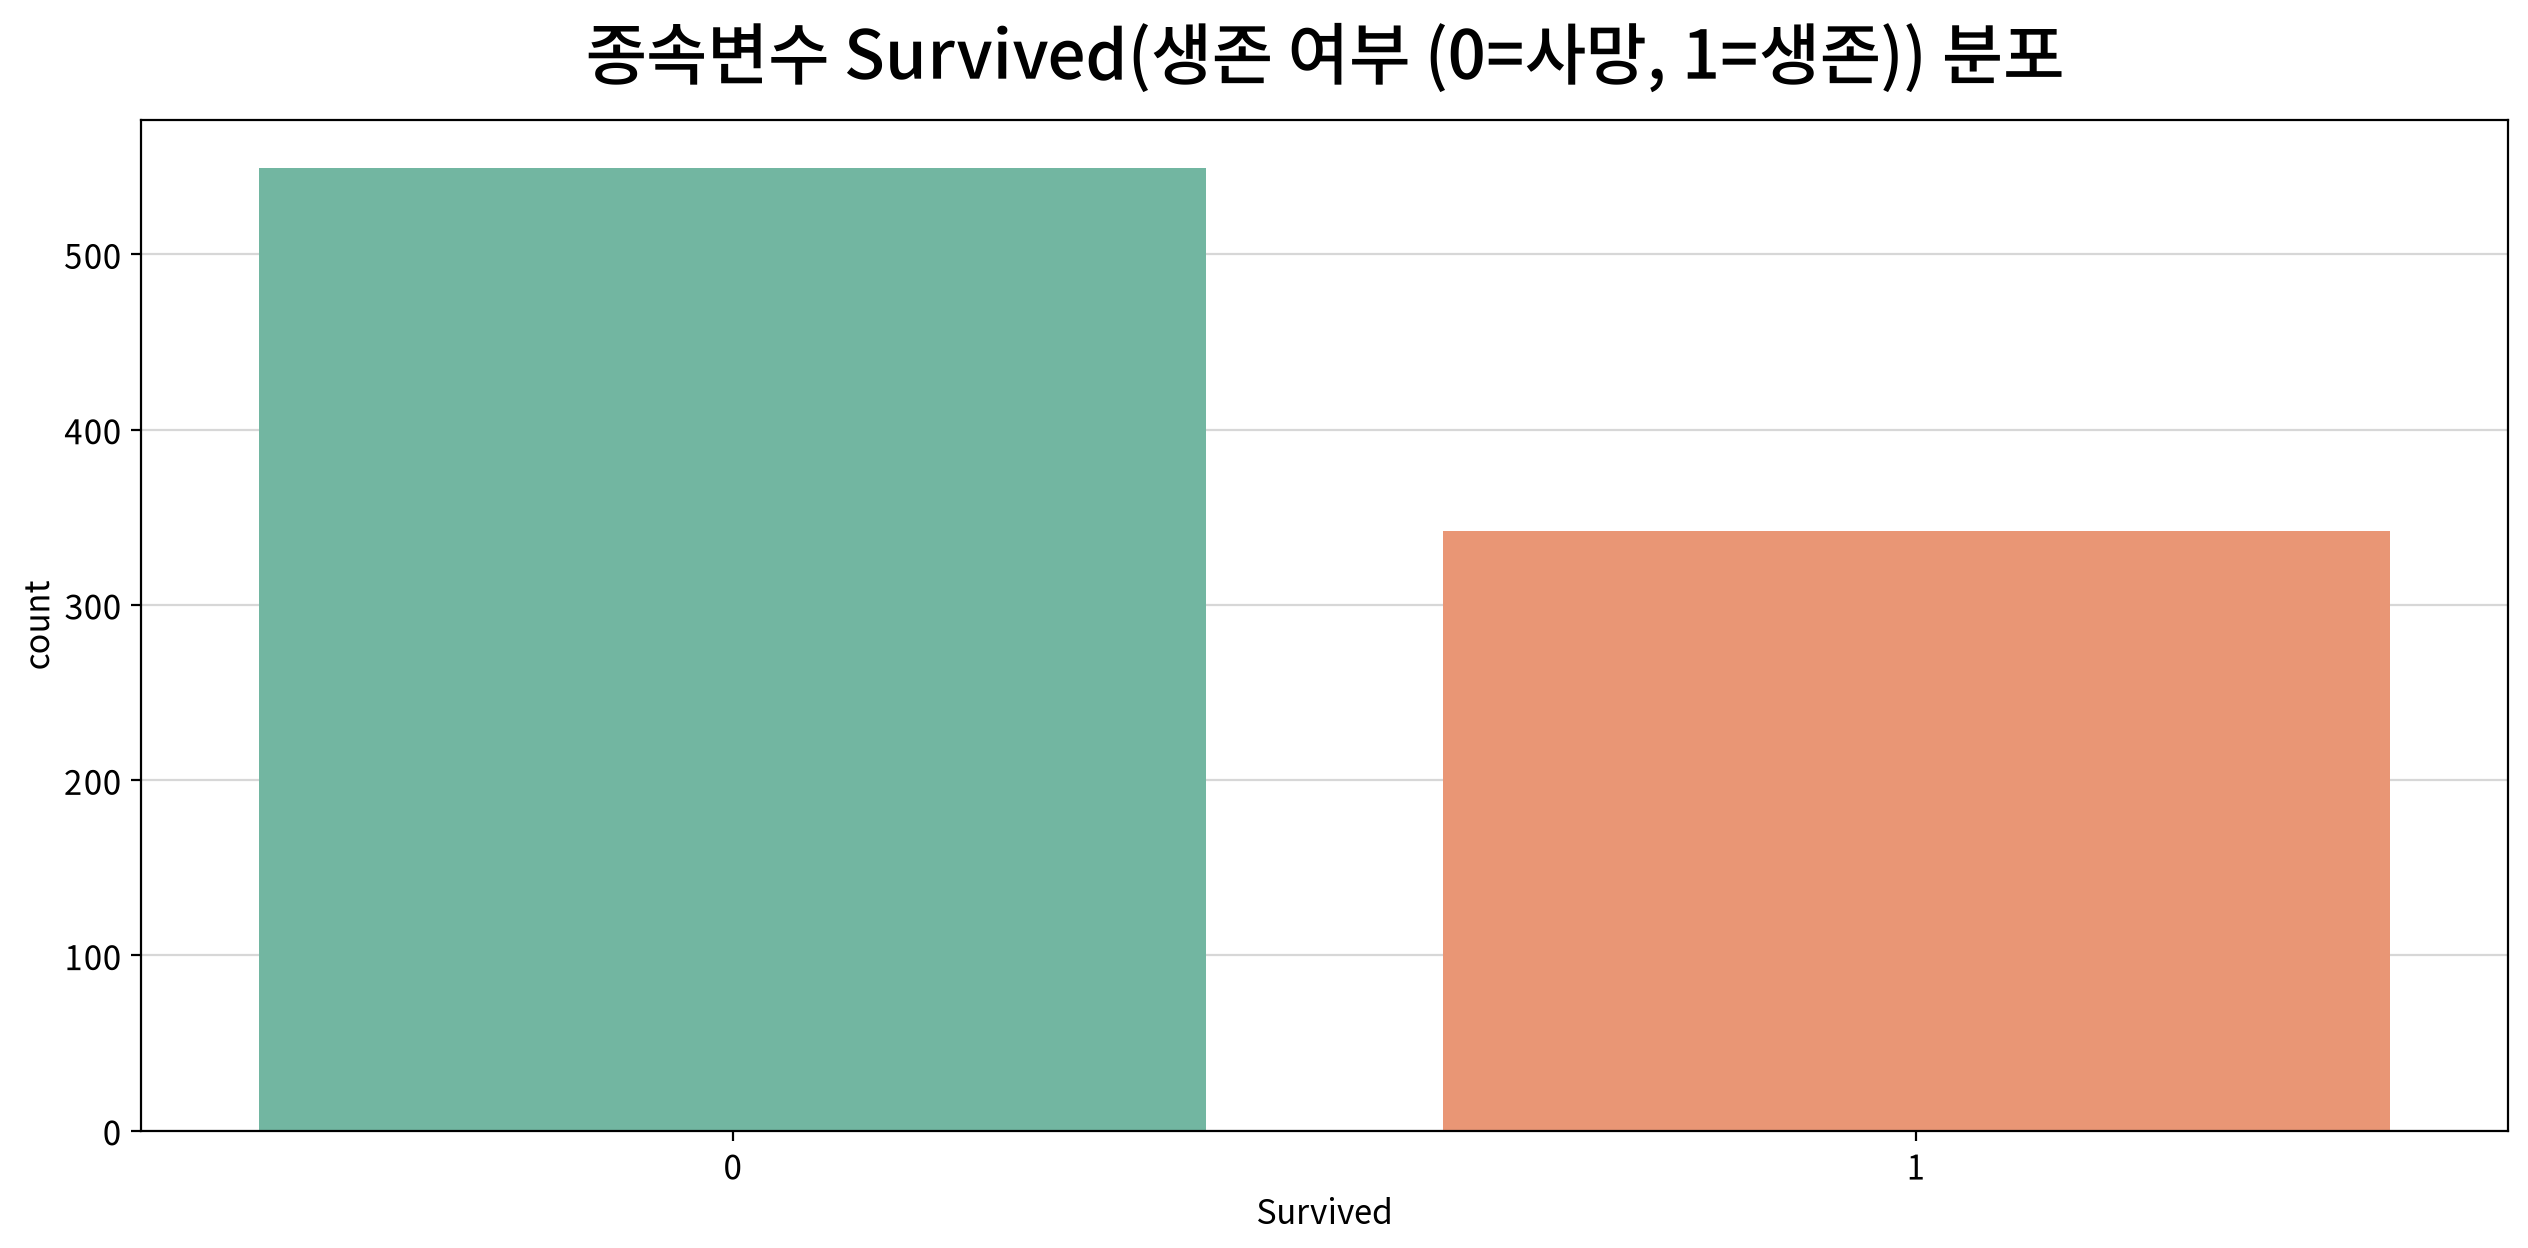

,count,unique,top,freq
Survived,891,2,0,549


,빈도,비율
Survived,,
0,549,0.616162
1,342,0.383838


In [18]:
# 명목형 분포는 카운트 플롯으로 처리한다.
my_plot.countplot(data=df, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

# 명목형 기술통계량
display(cat_desc[[target]].T)

# 추가적으로 빈도표 생성
freq = df[target].value_counts().rename("빈도").to_frame()
freq["비율"] = df[target].value_counts(normalize=True)
display(freq)

#### 💡 인사이트

| 점검 항목 | `Survived` 관찰값 |
|---|---|
| 범주 수 | 2 (0=사망 / 1=생존) → **이분형** 이므로 로지스틱 회귀 적용 가능 |
| 최빈 범주 | 사망 549건 (61.6%) |
| 최소 범주 | 생존 342건 (38.4%) |
| 균형 여부 | **약한 불균형** (62 : 38) |

- **정확도의 바닥값(baseline)은 61.6%** 다. 모두 "사망"이라고만 답하는 게으른 모형도 61.6%를 맞힌다.
  - 즉 정확도 70%짜리 모형은 **좋은 모형이 아니다.** 바닥값보다 8.4%p 나은 것에 불과하다.
  - Kaggle 대회의 평가 지표는 정확도 하나뿐이지만, 정확도를 볼 때는 **항상 이 바닥값과 비교**해야 한다.
- 62 : 38 정도의 불균형은 심각한 수준은 아니라 별도의 리샘플링 없이 진행하지만,
  **정확도 하나만 보지 말고 재현율·정밀도·AUC를 함께 확인**해야 한다.
- **생존 사건 수(342건)는 모형의 크기를 제한한다.** 경험칙(사건 10건당 변수 1개)으로 보면 **최대 30개 남짓**의 계수까지 안정적으로 추정할 수 있다. 더미 변수까지 합쳐도 여유가 있는 수준이다.

### 7-2. 명목형 `독립변수`에 대한 단변량 분석

- 명목형 독립변수도 **범주별 빈도의 쏠림**을 확인한다.
  - 한 범주에 관측치가 지나치게 적으면 그 더미변수의 계수가 불안정해지기 때문이다.

### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) 분포

Pclass,3,1,2
빈도,491.000000,216.000000,184.00000
비율,0.551066,0.242424,0.20651


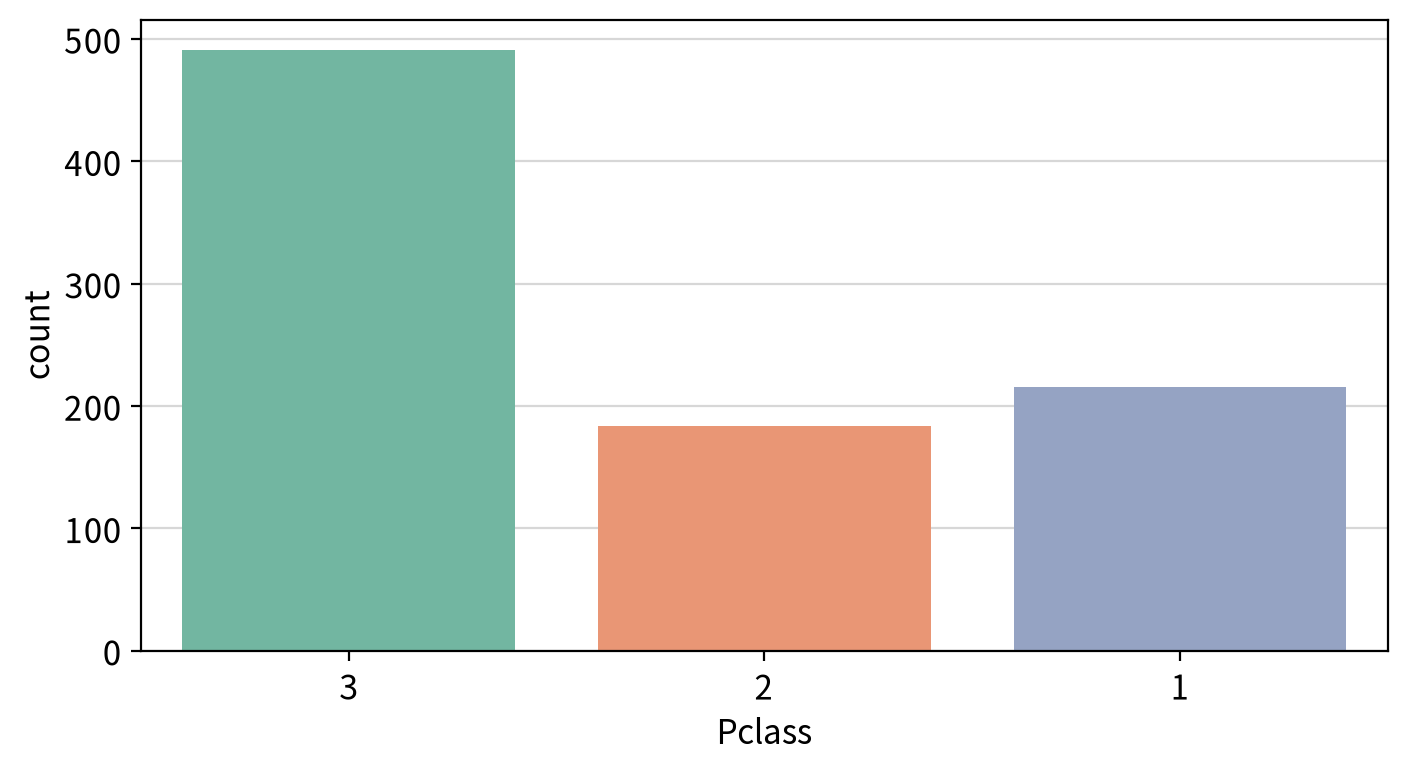

### ▶︎ Sex(성별) 분포

Sex,male,female
빈도,577.000000,314.000000
비율,0.647587,0.352413


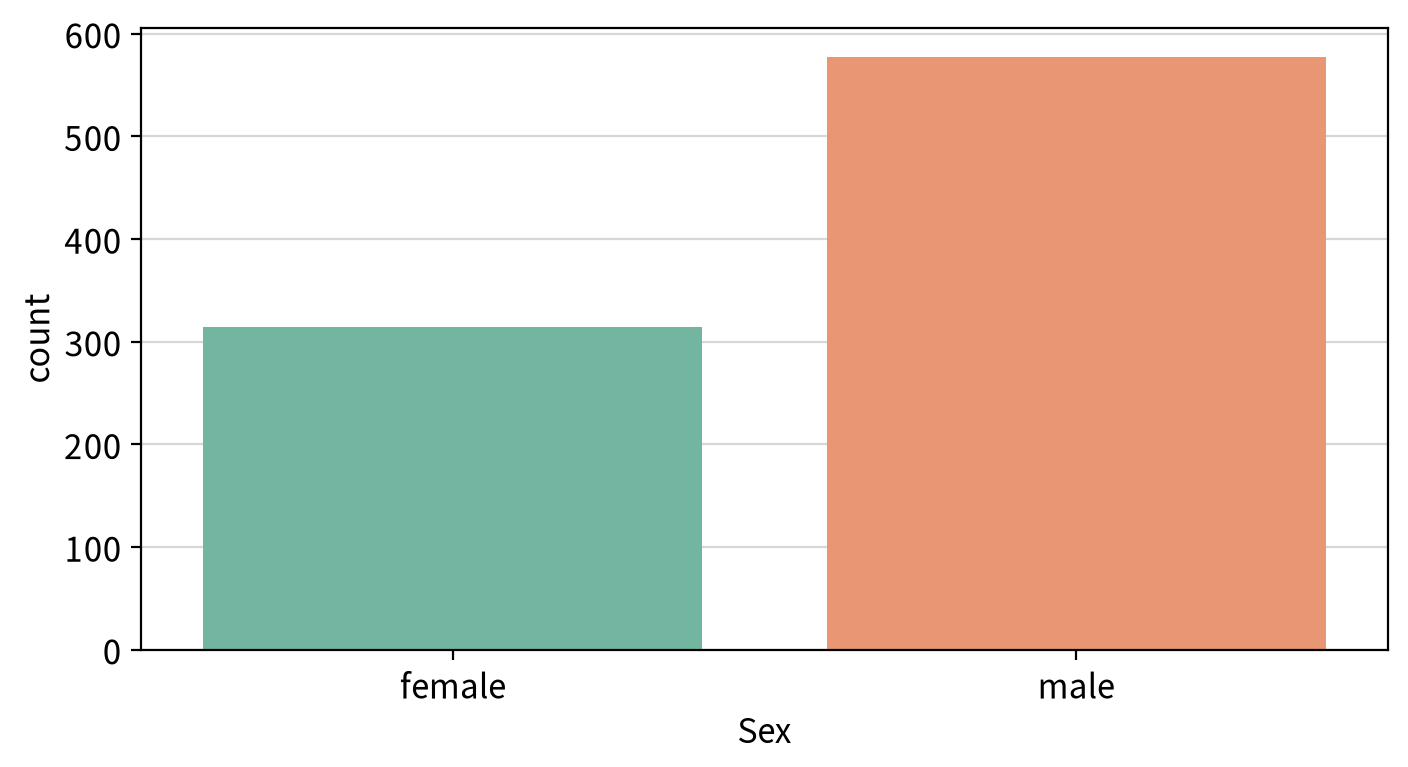

### ▶︎ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)) 분포

Embarked,S,C,Q
빈도,646.000000,168.000000,77.00000
비율,0.725028,0.188552,0.08642


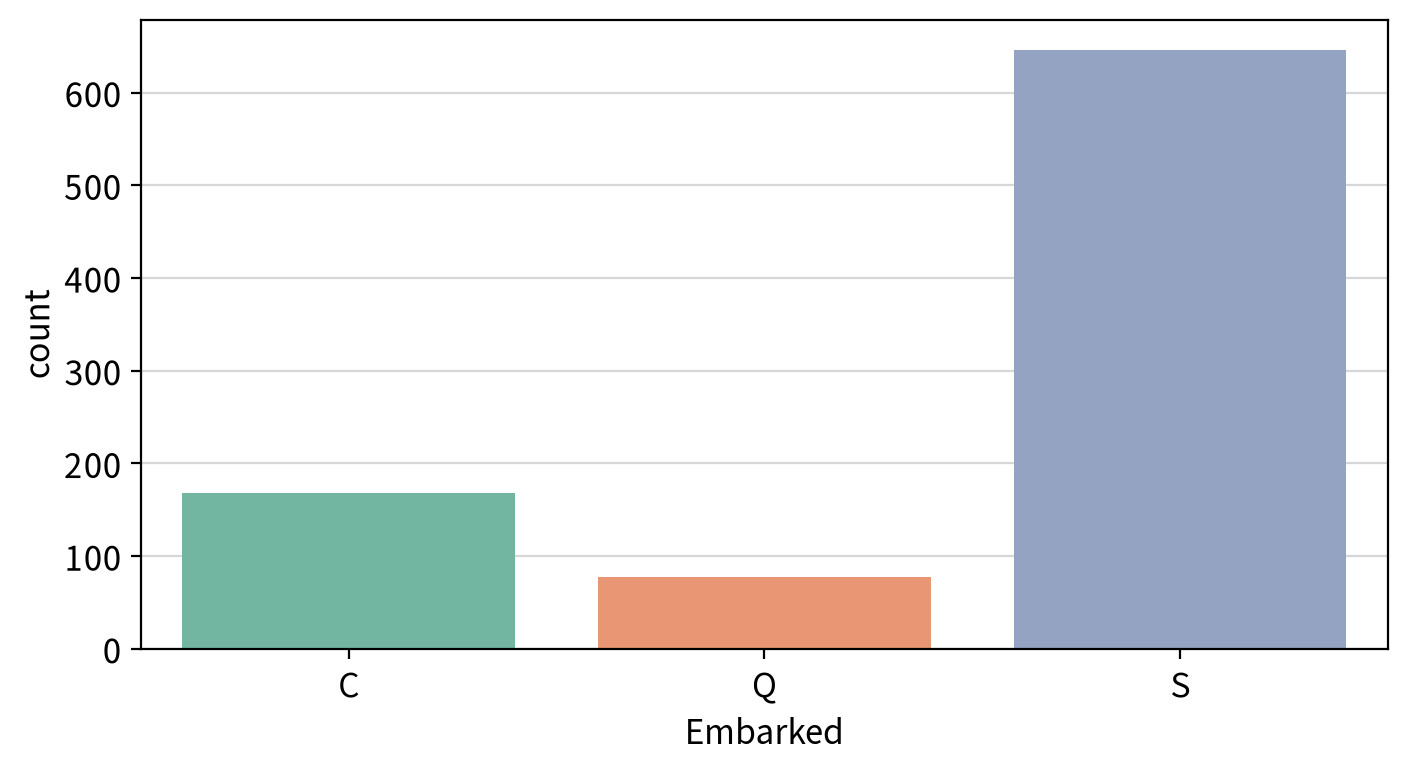

### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) 분포

Title,Mr,Miss,Mrs,Master,Officer
빈도,520.000000,185.000000,128.000000,40.000000,18.000000
비율,0.583614,0.207632,0.143659,0.044893,0.020202


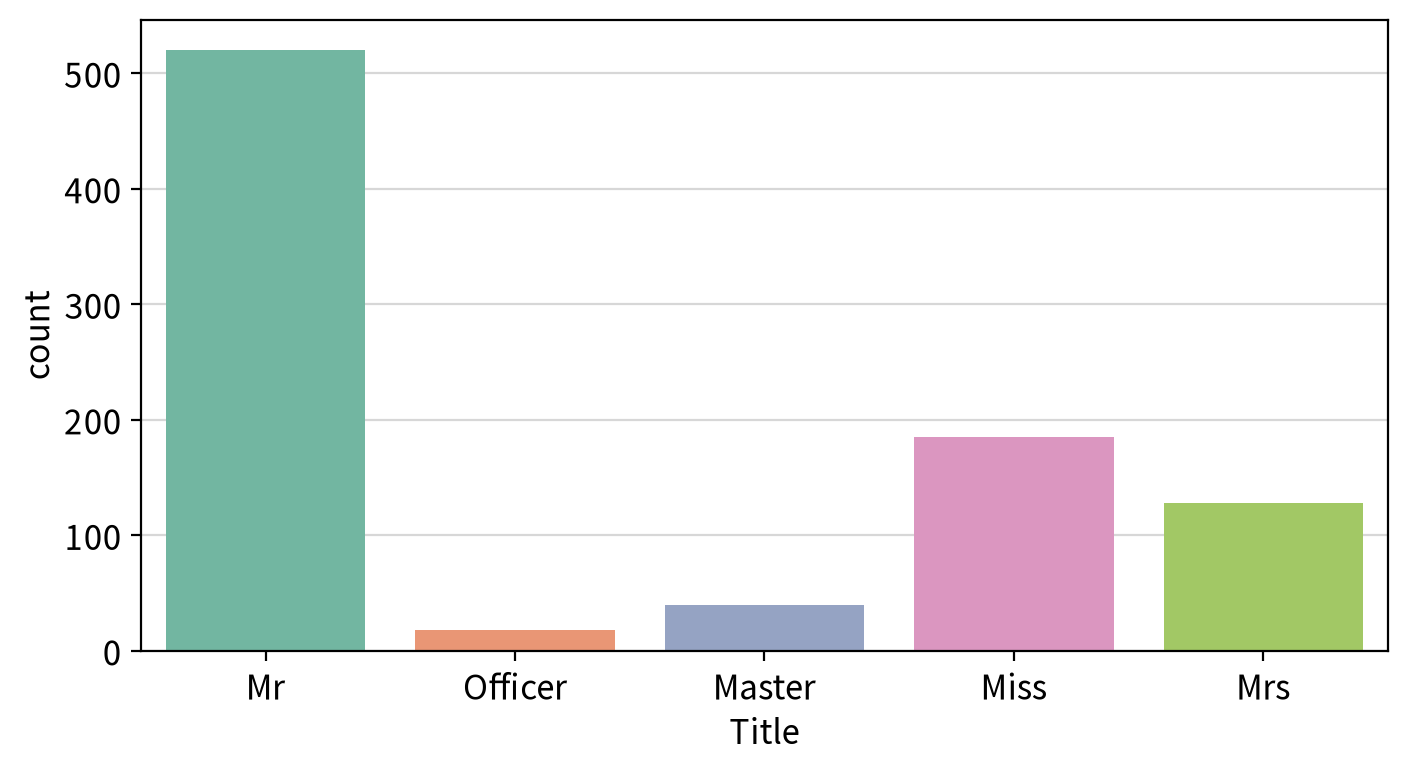

In [19]:
for n in nominal_cols:
    display(Markdown(f"### ▶︎ {n}({column_means[n]}) 분포"))
    freq = df[n].value_counts().rename("빈도").to_frame()
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq.T)
    
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", width=720, height=400)

#### 💡 인사이트

| 변수 | 범주 분포 | 판단 |
|---|---|---|
| `Pclass` | 3등급 491 (55.1%) · 1등급 216 (24.2%) · 2등급 184 (20.7%) | 3등급이 절반 이상이지만 나머지도 충분 |
| `Sex` | 남성 577 (64.8%) · 여성 314 (35.2%) | 문제 없음 |
| `Embarked` | S 646 (72.5%) · C 168 (18.9%) · **Q 77 (8.6%)** | Q가 적지만 77건이라 사용 가능 |
| **`Title`** | Mr 520 (58.4%) · Miss 185 (20.8%) · Mrs 128 (14.4%) · Master 40 (4.5%) · **Officer 18 (2.0%)** | **`Officer`가 경계선** |

- **가장 작은 범주가 `Title = Officer`의 18건**이다. 경험칙(한 범주에 최소 10~20건)의 **하한에 걸쳐 있다.**
  - 추정은 되지만 **신뢰구간이 넓게 나올 것**을 각오해야 한다.
  - **더 잘게 나눌수록 정보는 늘지만 각 칸의 표본은 줄어든다.** 파생변수를 만들 때 항상 마주치는 교환이다.
  - 원본 호칭 17종을 그대로 썼다면 1건짜리 범주가 8개나 생겨 **아예 추정이 불가능**했을 것이다.
    5종으로 통합한 판단이 여기서 정당화된다.
- **`Master` 40건도 많지 않다.** 하지만 #8-3에서 보듯 생존율이 다른 남성과 크게 달라 정보량이 큰 범주다.
- 3등급 승객이 절반을 넘는다는 사실 자체가 **타이타닉의 승객 구성**이다. 표본 편향이 아니라 모집단의 모습이다.

### 7-3. 연속형 독립변수에 대한 단변량 분석

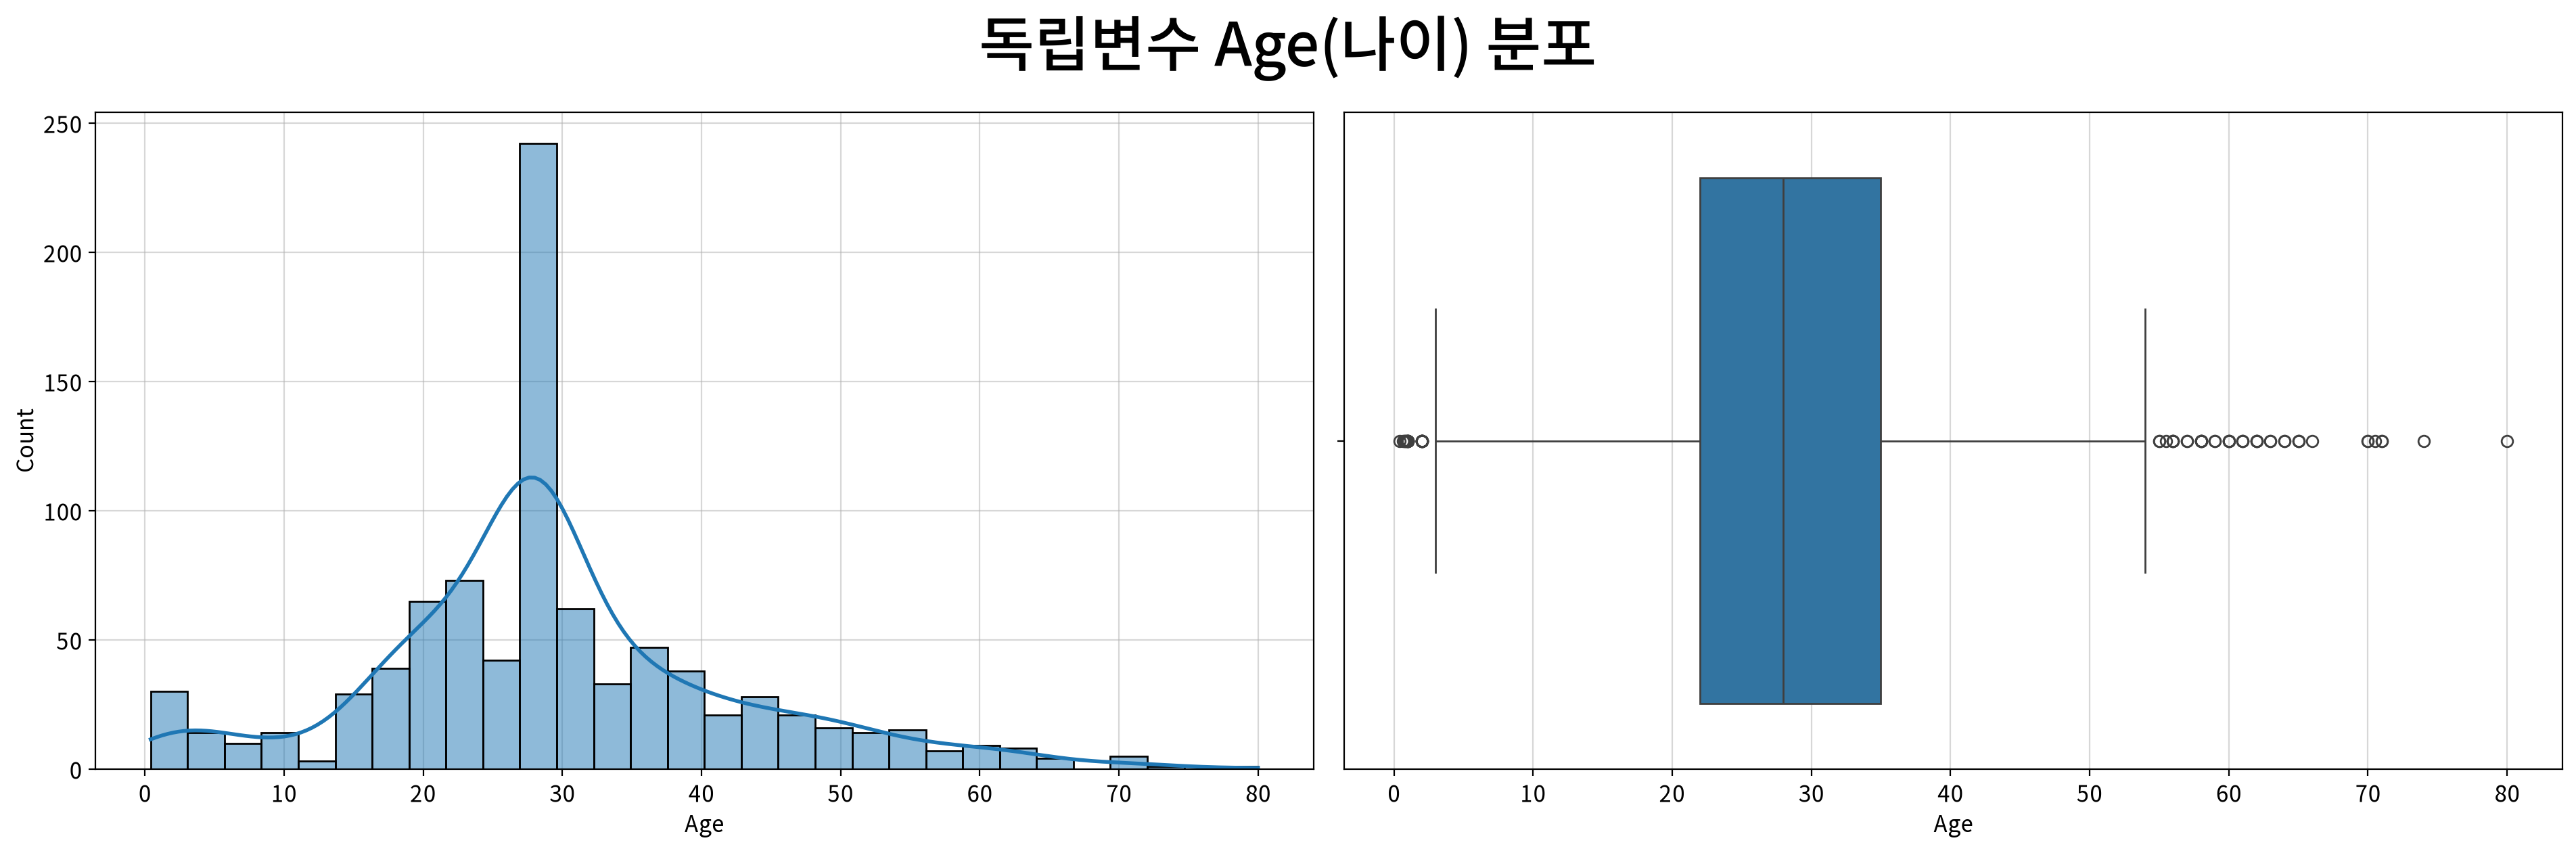

,Age
count,891.0
mean,29.361582
std,13.019697
min,0.42
25%,22.0
50%,28.0
75%,35.0
max,80.0
rel_diff,0.048628
rdiff_flag,similar


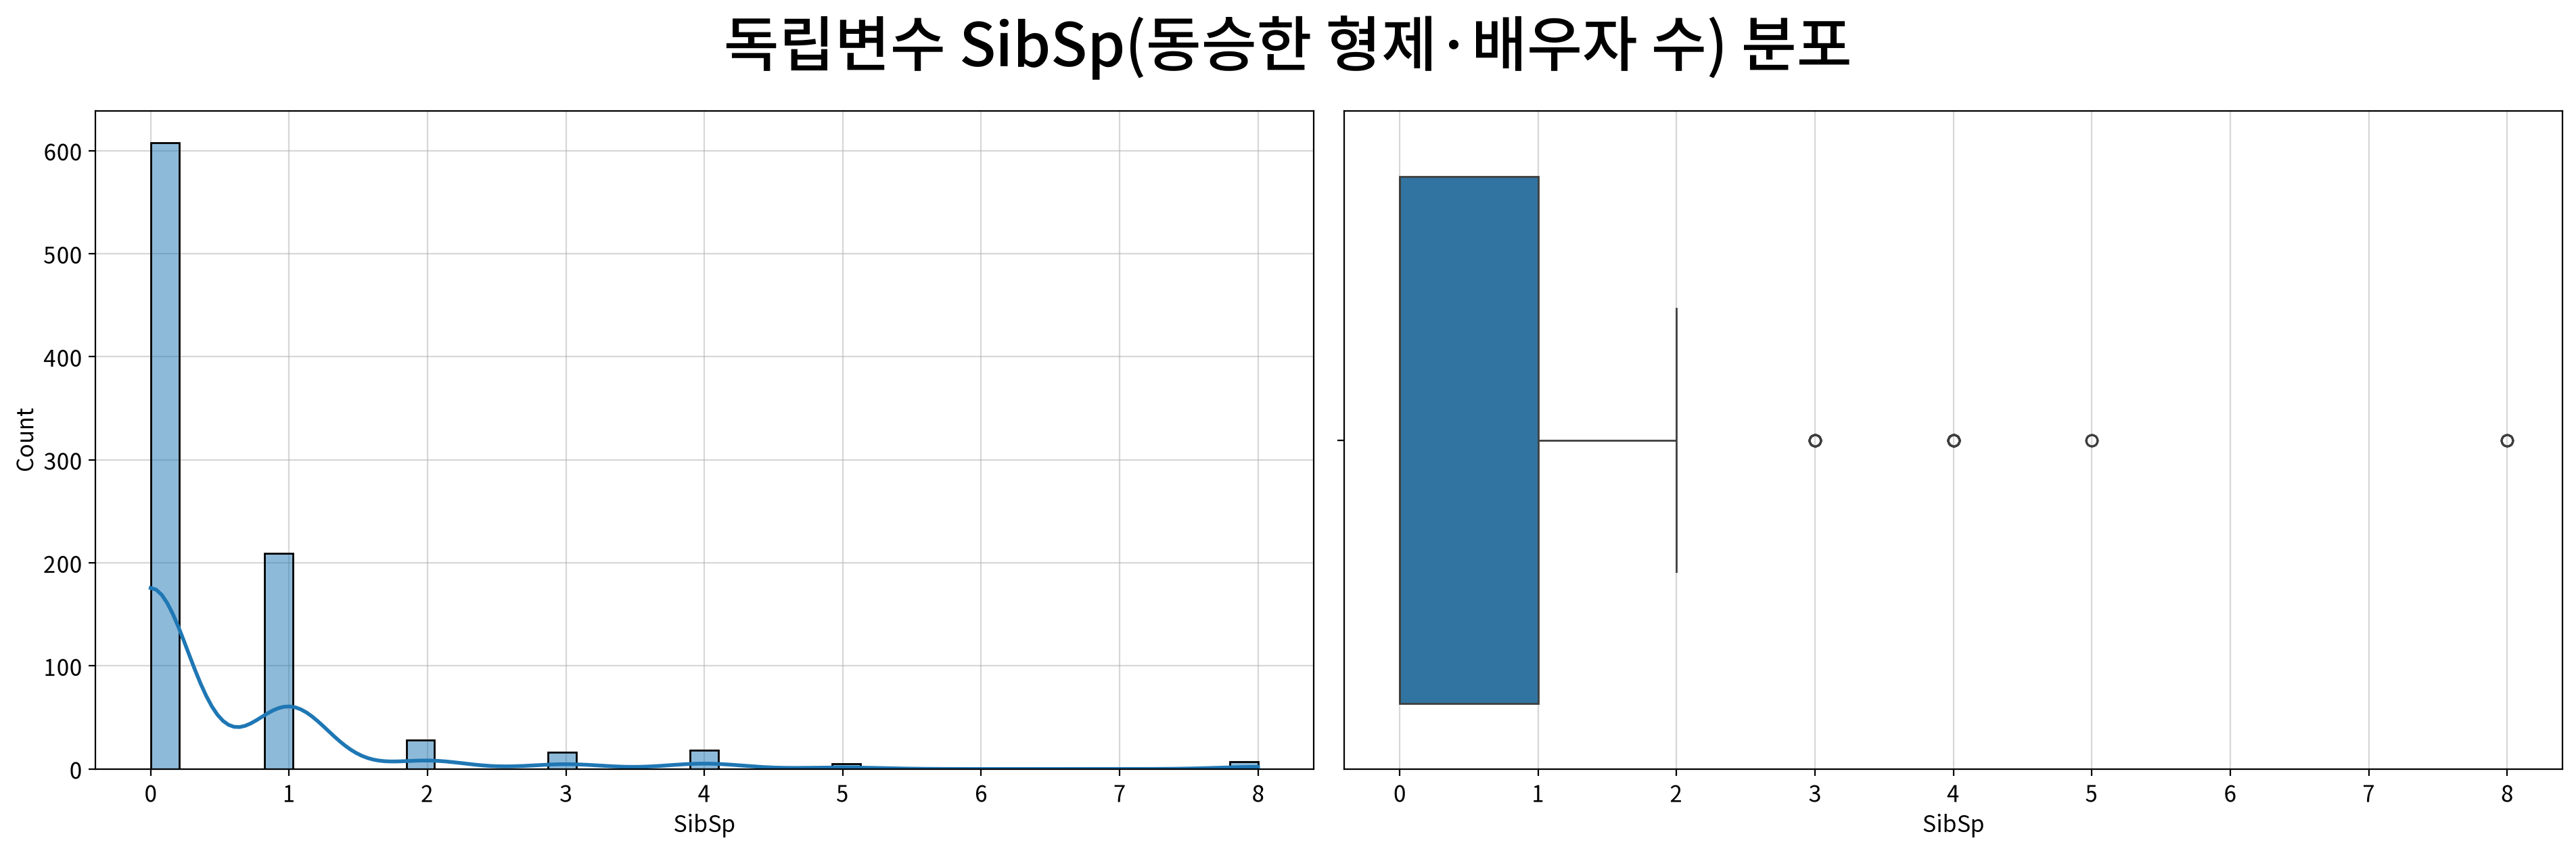

,SibSp
count,891.0
mean,0.523008
std,1.102743
min,0.0
25%,0.0
50%,0.0
75%,1.0
max,8.0
rel_diff,inf
rdiff_flag,large_diff


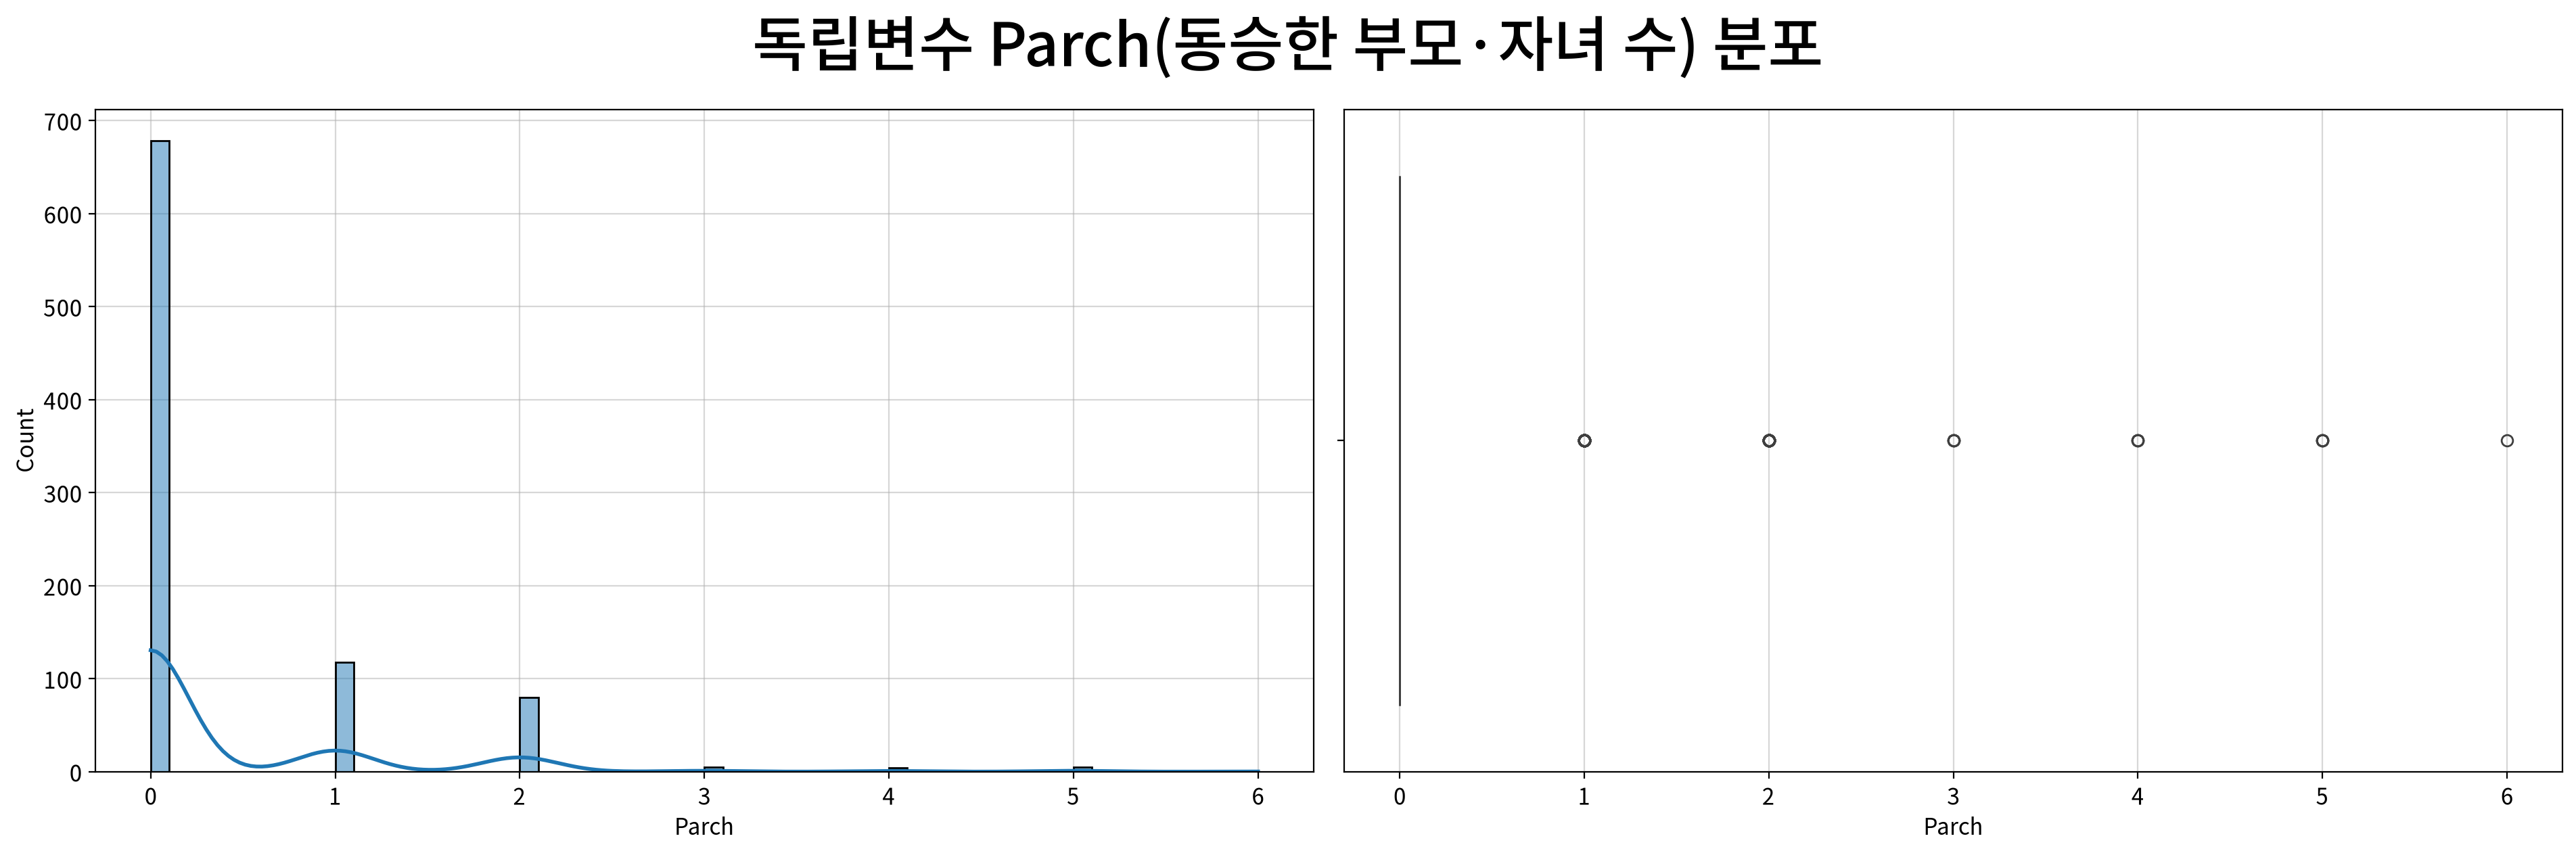

,Parch
count,891.0
mean,0.381594
std,0.806057
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,6.0
rel_diff,inf
rdiff_flag,large_diff


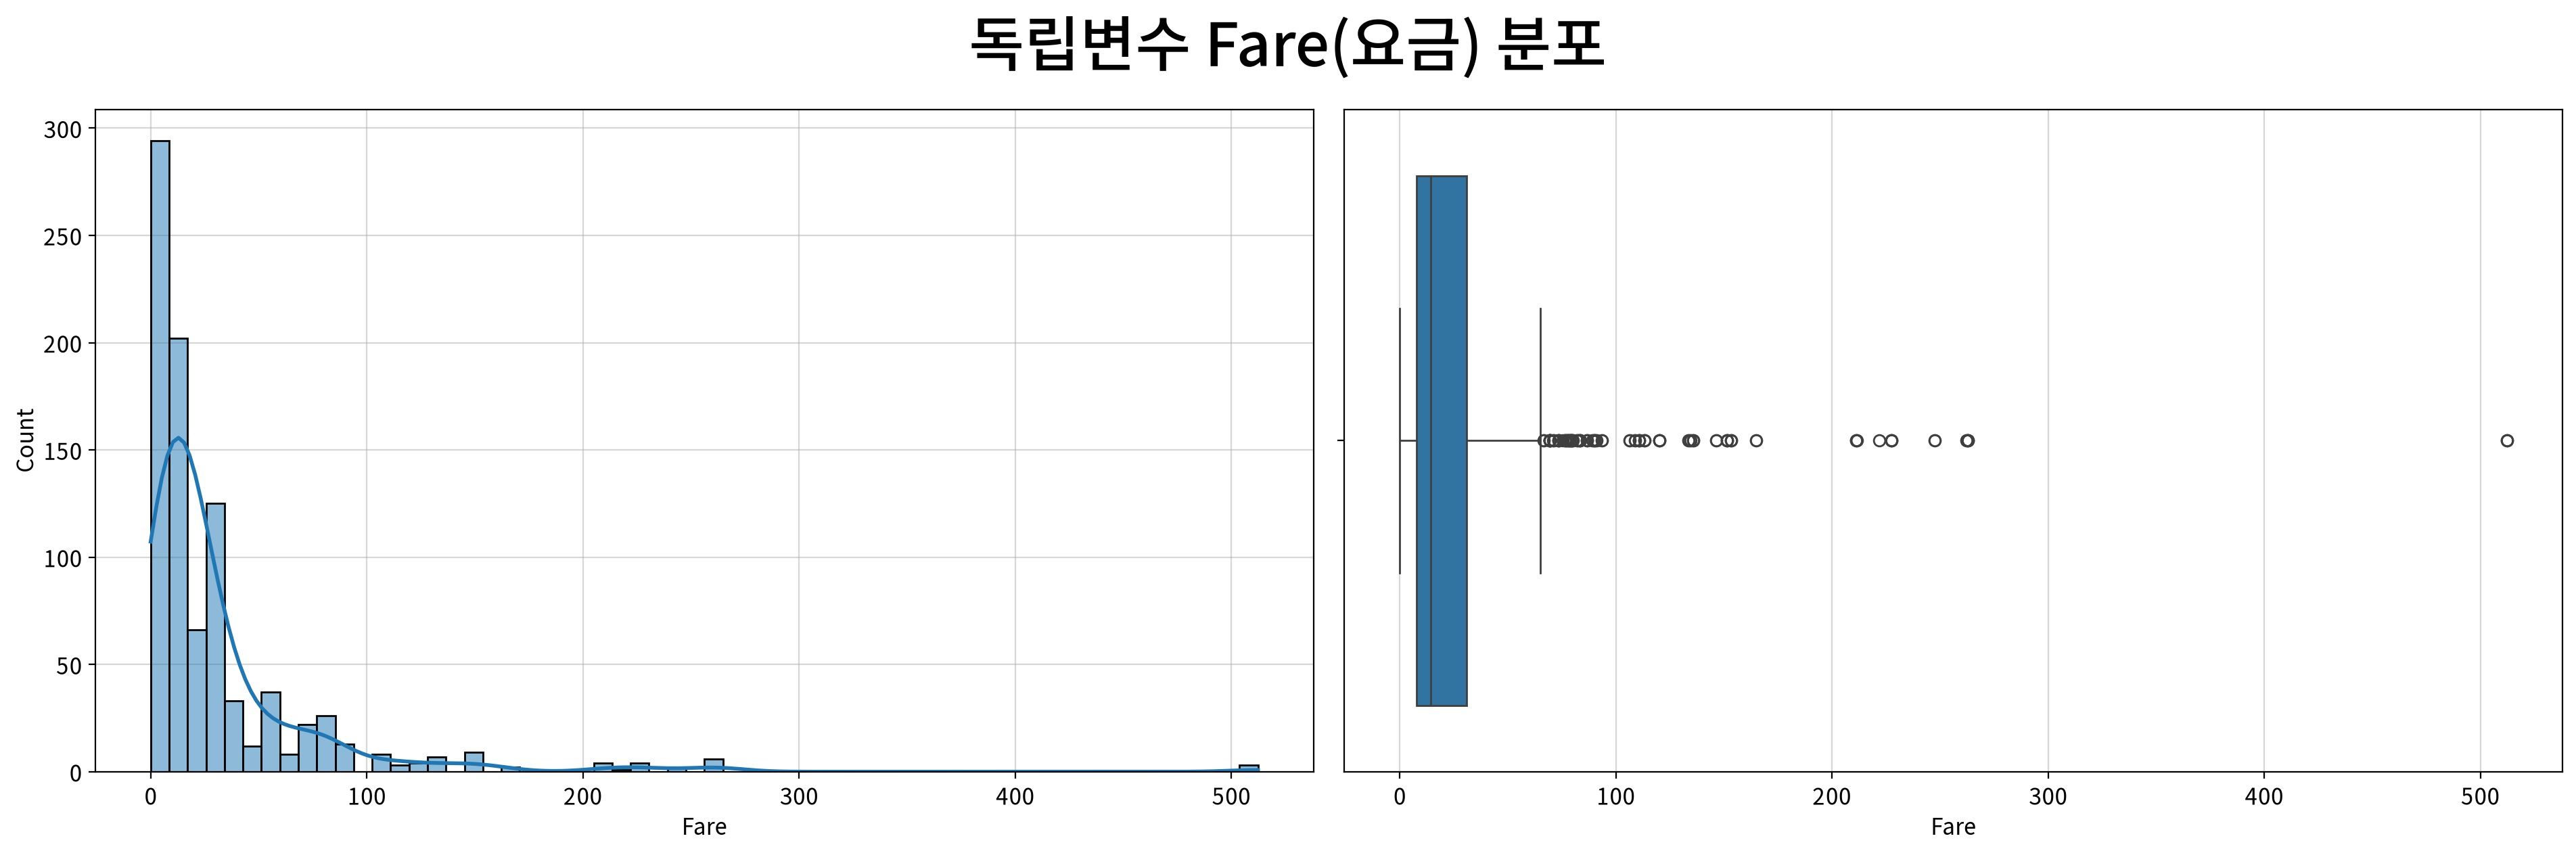

,Fare
count,891.0
mean,32.204208
std,49.693429
min,0.0
25%,7.9104
50%,14.4542
75%,31.0
max,512.3292
rel_diff,1.228017
rdiff_flag,large_diff


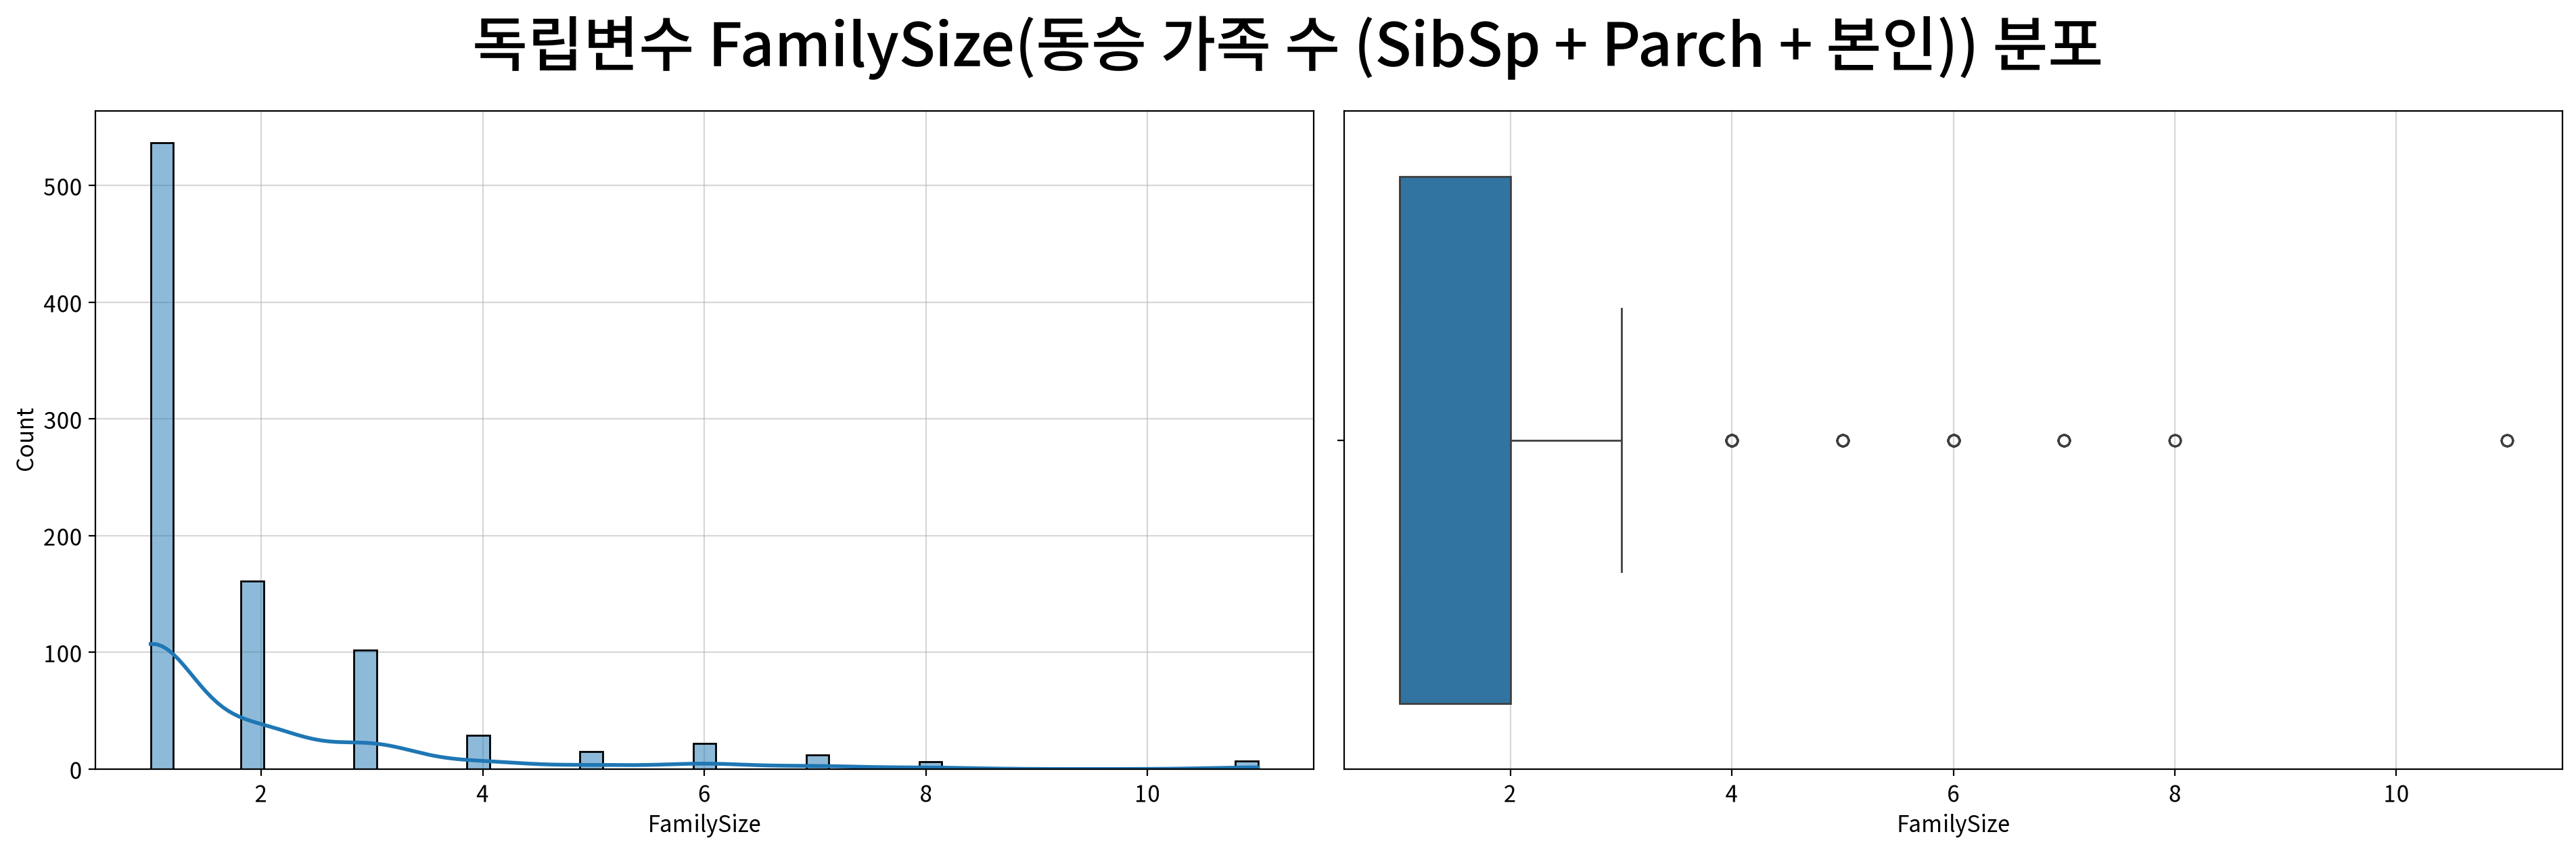

,FamilySize
count,891.0
mean,1.904602
std,1.613459
min,1.0
25%,1.0
50%,1.0
75%,2.0
max,11.0
rel_diff,0.904602
rdiff_flag,large_diff


In [20]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

#### 💡 인사이트

| 변수 | 분포 모양(왜도) | 봉우리 | 이상치 | 판단·조치 |
|---|---|---|---|---|
| `Age` | 약한 오른쪽 꼬리 (+0.51) | **28세에 인공 봉우리** | 66건 (7.4%) | 중앙값 대체의 흔적. 이상치는 영아·고령자로 실재하는 값 |
| `SibSp` | 심한 오른쪽 꼬리 (+3.70) | 0에 집중 | 46건 (5.2%) | **카운트 변수** — IQR 규칙 부적합 |
| `Parch` | 심한 오른쪽 꼬리 (+2.75) | 0에 집중 | **213건 (23.9%)** | **IQR = 0** → 이상치 판정 자체가 무의미 |
| `Fare` | 극심한 오른쪽 꼬리 (+4.79) | 저가 구간에 집중 | 116건 (13.0%) | 상위 요금은 실제 1등석 가격. 정보이지 오류가 아님 |
| **`FamilySize`** | 오른쪽 꼬리 (+2.73) | **1명에 집중 (60.3%)** | 91건 (10.2%) | **카운트 변수** — IQR = 1이라 4명부터 이상치 |

- **`Age`의 히스토그램 한가운데 뾰족한 막대가 서 있다.** 결측 177건을 중앙값 28세로 채운 자국이다(28세 승객 202명).
  실제 데이터가 아니라 **우리가 만들어 넣은 값**이므로, 이후 결과를 볼 때 항상 염두에 둬야 한다.
  - 대체 전 원자료의 표준편차는 14.53, 대체 후는 13.02로 **분포가 인위적으로 좁아졌다.**
- **`Parch`의 상자그림은 상자가 선 하나로 눌려 있다.** Q1 = Q3 = 0이라 상자에 두께가 없다.
  이런 변수에 IQR 이상치 대체를 적용하면 **0이 아닌 값이 전부 0으로 눌려 변수가 상수가 된다.**
- **`FamilySize`는 왜도가 +2.73으로 `SibSp`(+3.70)보다 완만하다.**
  - 둘을 더하면서 0이 몰려 있던 자리가 1로 옮겨가고 분포가 조금 퍼졌기 때문이다.
  - 그래도 **60.3%(537명)가 1명(단독 승객)** 이라 여전히 한쪽으로 심하게 쏠려 있다.
  - **IQR = 1이라 상한이 3.5**다. 즉 **가족 4명부터 전부 이상치**로 잡힌다. `Parch`와 같은 함정이므로
    **이상치 대체 대상에서 제외**해야 한다.
- **`Fare`는 평균(32.20)이 중앙값(14.45)의 2.2배**이고 최댓값은 512.33이다. 상위 13.0%가 1등급 고가 객실 요금이다.
- **⚠️ 여기서 로그변환을 하지 않는다.** 로지스틱 회귀는 **독립변수의 정규성을 가정하지 않기** 때문이다.
  왜도가 크다는 사실은 기록해 두되, 변환 여부는 모형 단계에서 **로짓 선형성 검정**으로 결정한다.

---
## #8. 이변량 분석

### 8-1. T-Test (x: **연속형 독립변수** → y: **2집단 명목형 종속변수**)

- `test_independent()` 는 정규성을 먼저 검정하고, 정규성이 기각되면 **Mann-Whitney U 검정**으로 자동 전환한다.

#### ▶︎ Age(나이) → Survived

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided      97978.5   0.2697        False  0 = 1
                    less           97978.5   0.8652        False  0 ≥ 1
                    greater        97978.5   0.1348        False  0 ≤ 1

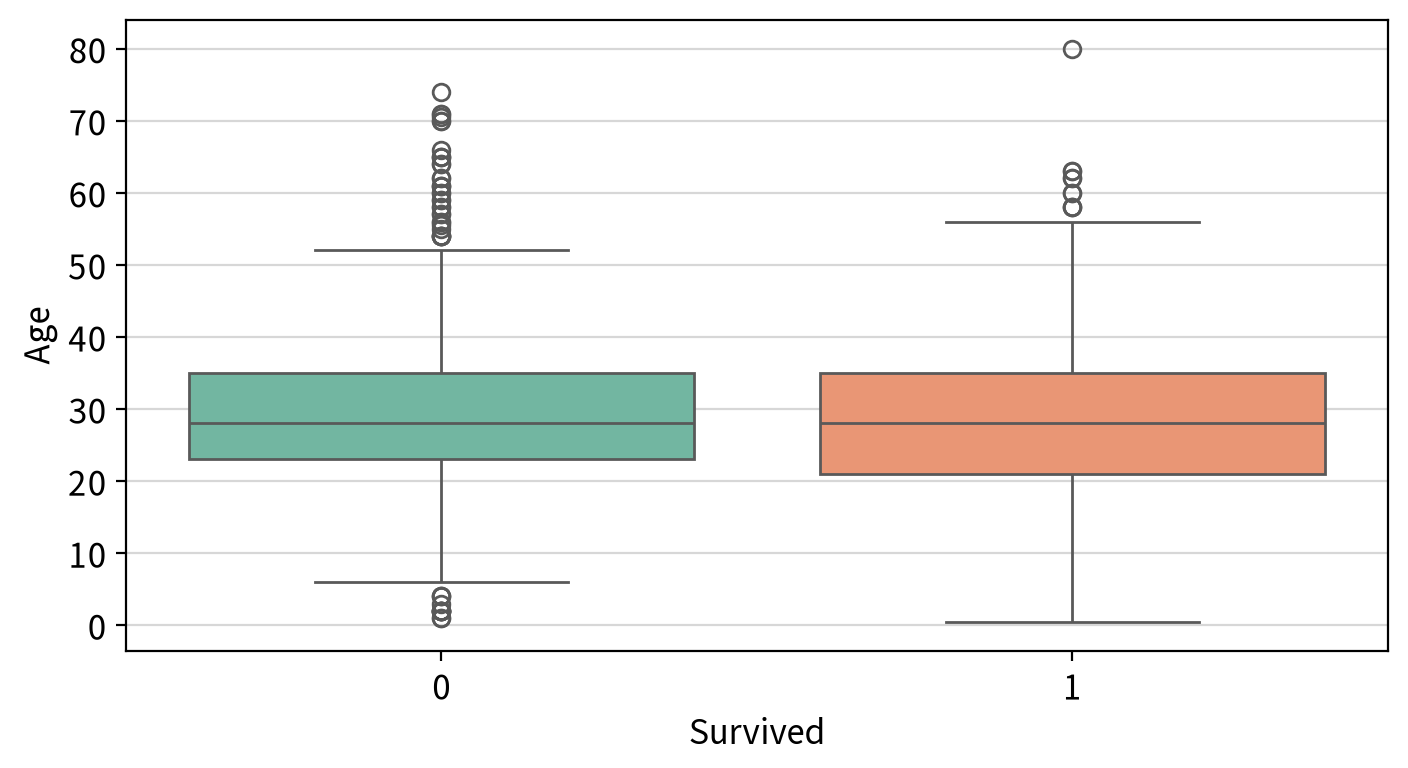

#### ▶︎ SibSp(동승한 형제·배우자 수) → Survived

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided      85775.0    0.008         True  0 ≠ 1
                    less           85775.0    0.004         True  0 < 1
                    greater        85775.0    0.996        False  0 ≤ 1

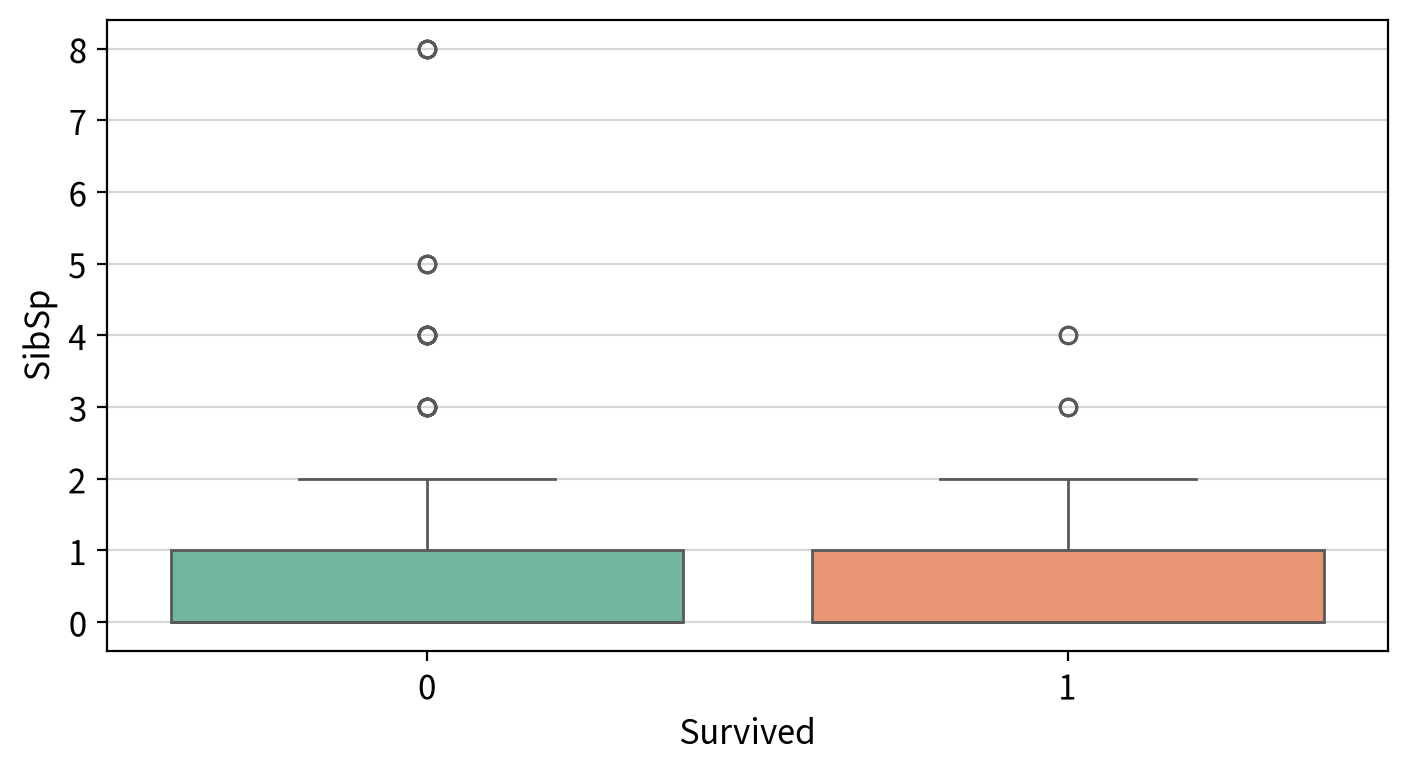

#### ▶︎ Parch(동승한 부모·자녀 수) → Survived

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided      82385.0      0.0         True  0 ≠ 1
                    less           82385.0      0.0         True  0 < 1
                    greater        82385.0      1.0        False  0 ≤ 1

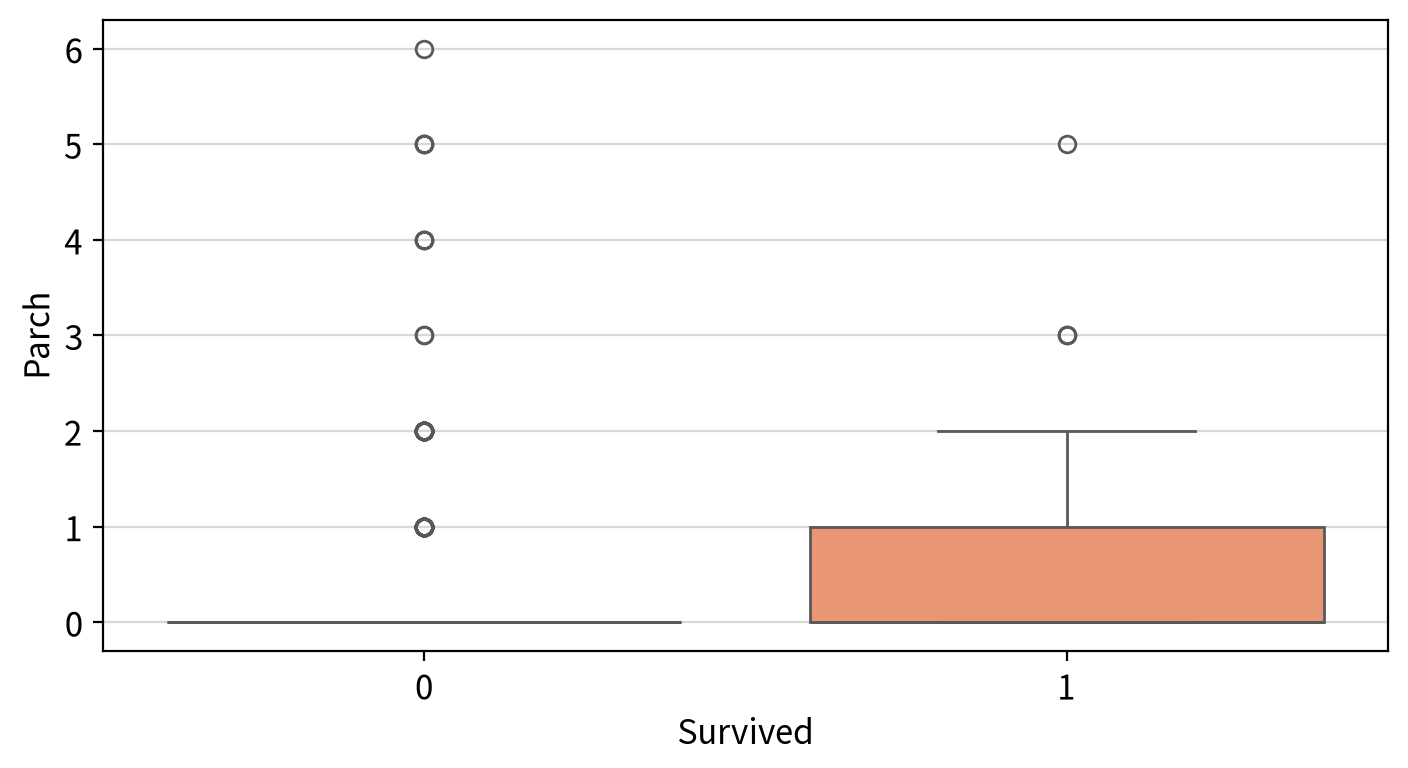

#### ▶︎ Fare(요금) → Survived

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided      57806.5      0.0         True  0 ≠ 1
                    less           57806.5      0.0         True  0 < 1
                    greater        57806.5      1.0        False  0 ≤ 1

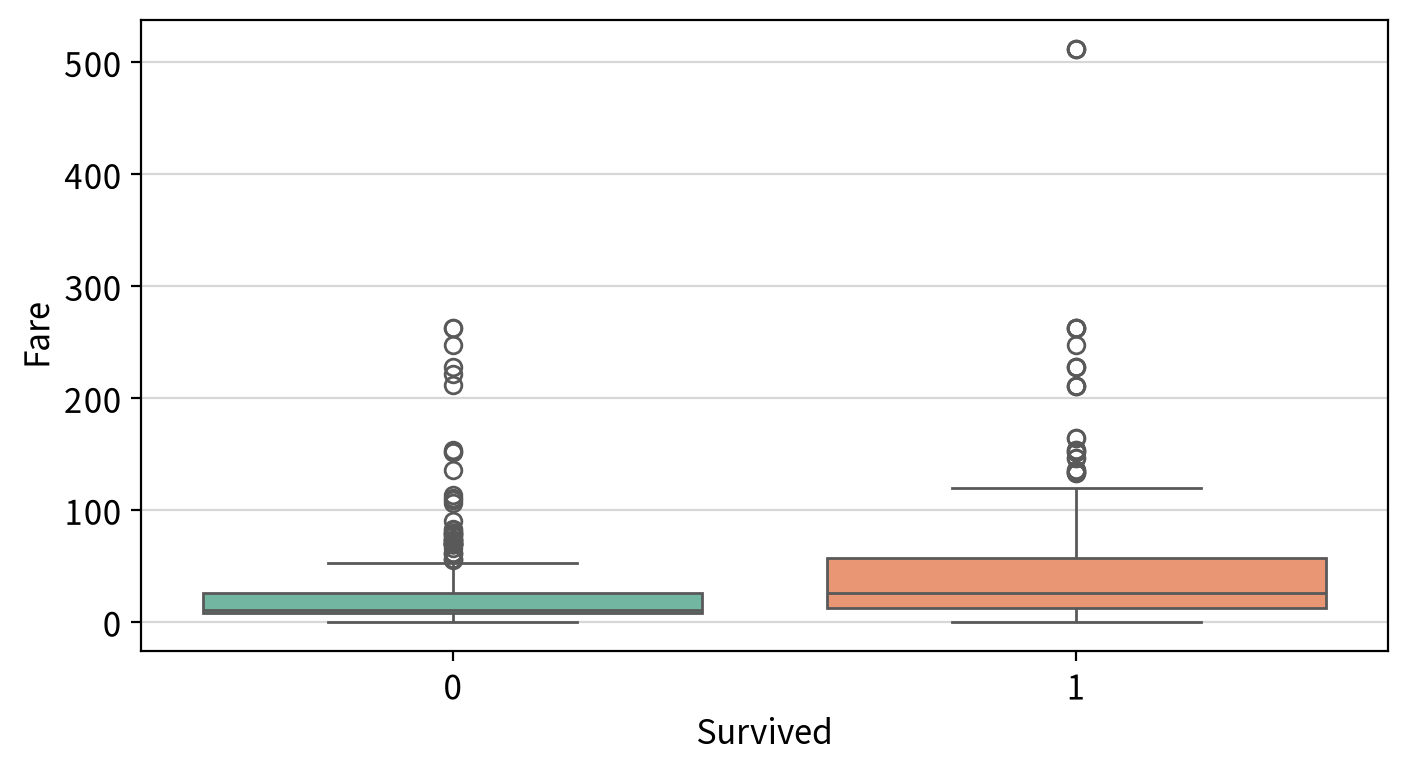

#### ▶︎ FamilySize(동승 가족 수 (SibSp + Parch + 본인)) → Survived

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided      77659.0      0.0         True  0 ≠ 1
                    less           77659.0      0.0         True  0 < 1
                    greater        77659.0      1.0        False  0 ≤ 1

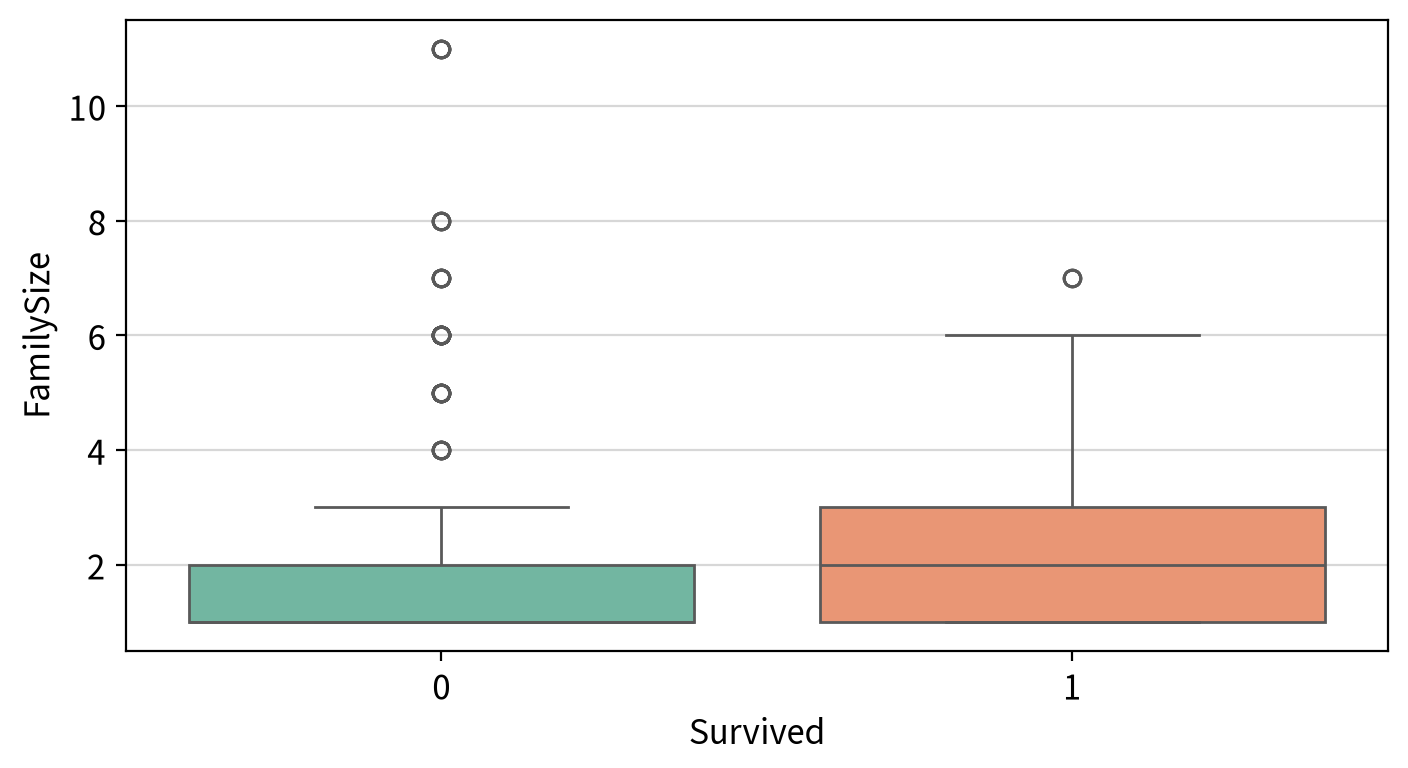

In [21]:
# 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    # -> 선형회귀 때와 hue/values 가 서로 뒤바뀐다. (종속변수가 집단 기준이 되므로)
    wide_df = my_prep.long2wide(df, hue=target, values=f)
    display(my_stats.test_independent(wide_df,
                group1=wide_df.columns[0], group2=wide_df.columns[1], plot=False))

    # 시각화: 종속변수 집단별 분포 비교
    my_plot.boxplot(data=df, x=target, y=f, hue=target, palette="Set2",
                    width=720, height=400)

### 8-2. `FamilySize` 값별 생존율

- T검정(Mann-Whitney U)은 두 집단의 **순위 중심 위치**만 비교한다. 즉 "생존자 쪽이 대체로 크다/작다"까지만 말해 준다.
- 그런데 `FamilySize` 는 값이 1~11인 **카운트 변수**라 **값별 생존율의 모양**을 직접 볼 수 있다.
  순위 비교가 놓치는 것이 없는지 확인한다.

,사망률,생존률,인원수
FamilySize,,,
1,0.696462,0.303538,537
2,0.447205,0.552795,161
3,0.421569,0.578431,102
4,0.275862,0.724138,29
5,0.800000,0.200000,15
6,0.863636,0.136364,22
7,0.666667,0.333333,12
8,1.000000,0.000000,6
11,1.000000,0.000000,7


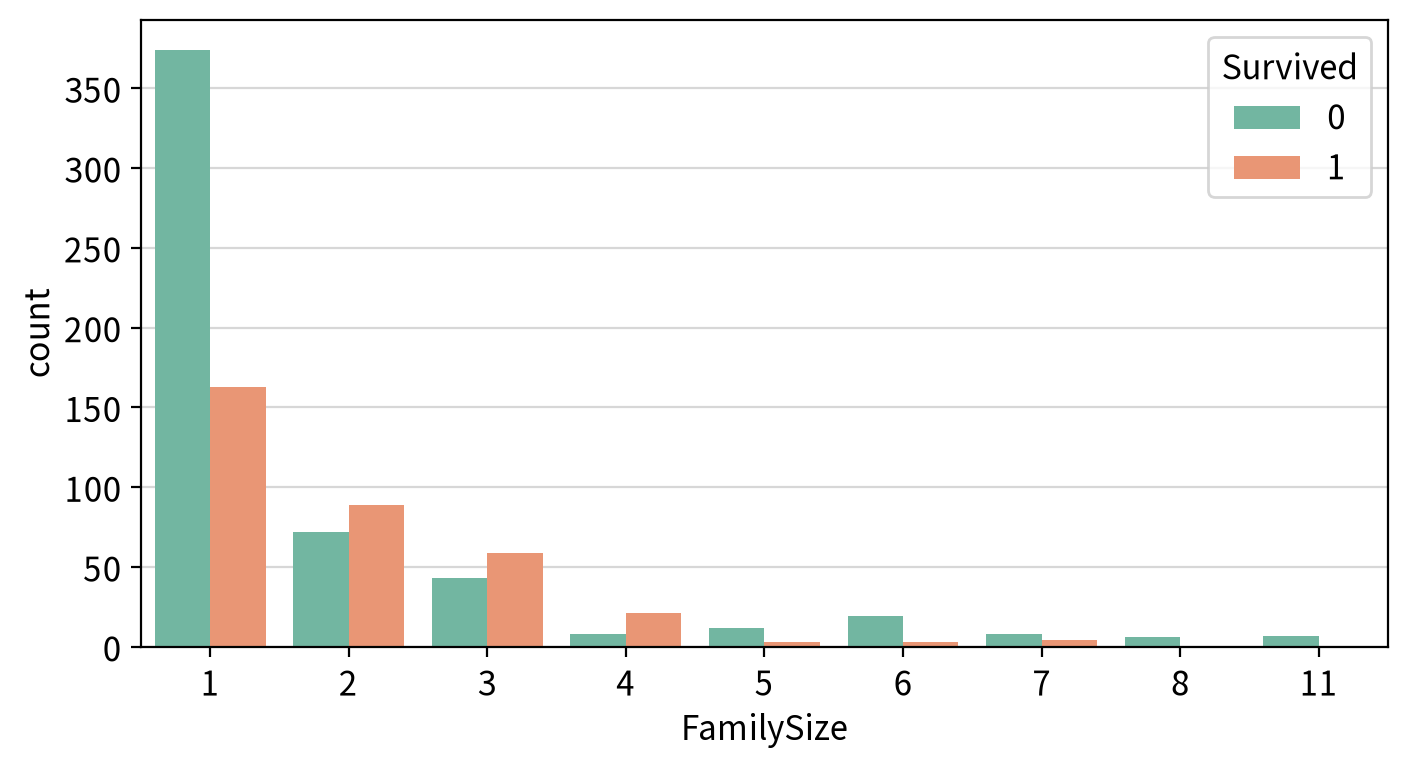

In [22]:
# 가족 규모별 생존율을 직접 계산한다
fs_rate = df.groupby("FamilySize", observed=True)[target].value_counts(normalize=True).unstack()
fs_rate.columns = ["사망률", "생존률"]
fs_rate["인원수"] = df["FamilySize"].value_counts().sort_index()
display(fs_rate)

# 시각화: 가족 규모별 생존 빈도
my_plot.countplot(data=df, x="FamilySize", hue=target, palette="Set2", 
                  width=720, height=400)

#### 💡 인사이트

**5종 모두 정규성이 기각되어 Mann-Whitney U 검정으로 전환**되었다. 사망(0) 집단과 생존(1) 집단의 비교 결과는 다음과 같다.

| 변수 | 검정 방법 | 유의확률(양측) | 집단 차이 | 평균 (사망 → 생존) | 중앙값 (사망 → 생존) | 단독 채택 |
|---|---|---|---|---|---|---|
| `Fare` | Mann-Whitney U | < 0.001 | 유의 | 22.12 → **48.40** | 10.50 → **26.00** | ✅ |
| **`FamilySize`** | Mann-Whitney U | < 0.001 | 유의 | 1.88 → 1.94 | 1 → **2** | ✅ |
| `Parch` | Mann-Whitney U | < 0.001 | 유의 | 0.33 → 0.47 | 0 → 0 | ✅ |
| `SibSp` | Mann-Whitney U | 0.008 | 유의 | **0.55 → 0.47** | 0 → 0 | ✅ |
| `Age` | Mann-Whitney U | **0.270** | **차이 없음** | 30.03 → 28.29 | 28 → 28 | 🟡 보류 |

- **`Fare`의 차이가 가장 크다.** 생존자의 평균 요금이 사망자의 **2.2배**, 중앙값은 **2.5배**다. 요금은 곧 객실 등급이므로
  이 차이의 상당 부분은 `Pclass`와 겹칠 것으로 예상된다.
- **`SibSp`는 평균으로 보면 오히려 사망자가 더 많다(0.55 > 0.47).** 그런데 순위 검정은 **생존자 쪽이 크다(단측 p = 0.004)** 고 말한다. 방향이 엇갈린다.
  - 형제·배우자가 **1명 이상** 있는 비율은 생존자 38.6% > 사망자 27.5%다. → 1~2명 동반은 생존에 유리했다.
  - 반면 **3명 이상**인 대가족 비율은 사망자 7.1% > 생존자 2.0%다. → 소수의 대가족이 사망자의 평균을 끌어올렸다.
  - Mann-Whitney U는 평균이 아니라 **순위**를 비교하는 검정이라, 극단값보다 다수의 1명 동반 효과를 잡아낸 것이다.
- **`FamilySize`는 평균 차이가 0.06명뿐**(1.88 vs 1.94)인데도 유의하다. 같은 이유다.
  - 가족 규모별 생존율 표가 그 이유를 보여준다. **1명 30.4% → 2명 55.3% → 3명 57.8% → 4명 72.4%까지 오르다가
    5명 20.0% → 6명 13.6%로 급락하고, 8명·11명 가족은 전원(13명) 사망한 역U자**다. **평균 하나로는 이 모양을 표현할 수 없다.**
  - 양 끝이 서로를 상쇄해 평균 차이가 거의 사라진 것이다.
  - → **"유의하다"는 사실보다 "어떻게 유의한가"가 중요하다.** 모형에 `FamilySize`를 **직선 그대로** 넣으면 이 모양을 담지 못하므로,
    **구간화(단독 / 2~4명 / 5명 이상)** 를 검토해야 한다.
- **`Age`는 p = 0.270으로 무관하게 나온다.** 하지만 이것을 "나이는 생존과 상관없다"로 읽으면 안 된다.
  - 어린이는 우선 구조되어 생존율이 높고, 고령자는 생존율이 낮다. **양 끝이 반대 방향이라 순위 비교에서 상쇄**된다. (#8-4에서 연령대별로 확인)
  - 게다가 결측 177건을 중앙값 28세로 채워 넣어 **두 집단의 중앙값이 모두 정확히 28세**가 되었다.
  - → **이 단계의 "무관"은 최종 판정이 아니다.**

### 8-3. 교차분석 (x: **명목형 독립변수** → y: **명목형 종속변수**)

- 명목형 독립변수가 있을 경우 **카이제곱 독립성 검정**을 수행한다.
  - 명목형 독립변수가 없을 경우 출력 결과가 없을 수 있다.
- 효과 크기는 **Cramer's V** 로 본다. 유의확률은 "관계가 있는가", V는 "얼마나 센가"를 말한다.

#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) → Survived

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Pclass,Survived,Chi-square test of independence,102.889,2,0.0,True,0.3398,Moderate,70.63,True


Survived,0,1
Pclass,,
3,0.757637,0.242363
2,0.527174,0.472826
1,0.370370,0.629630


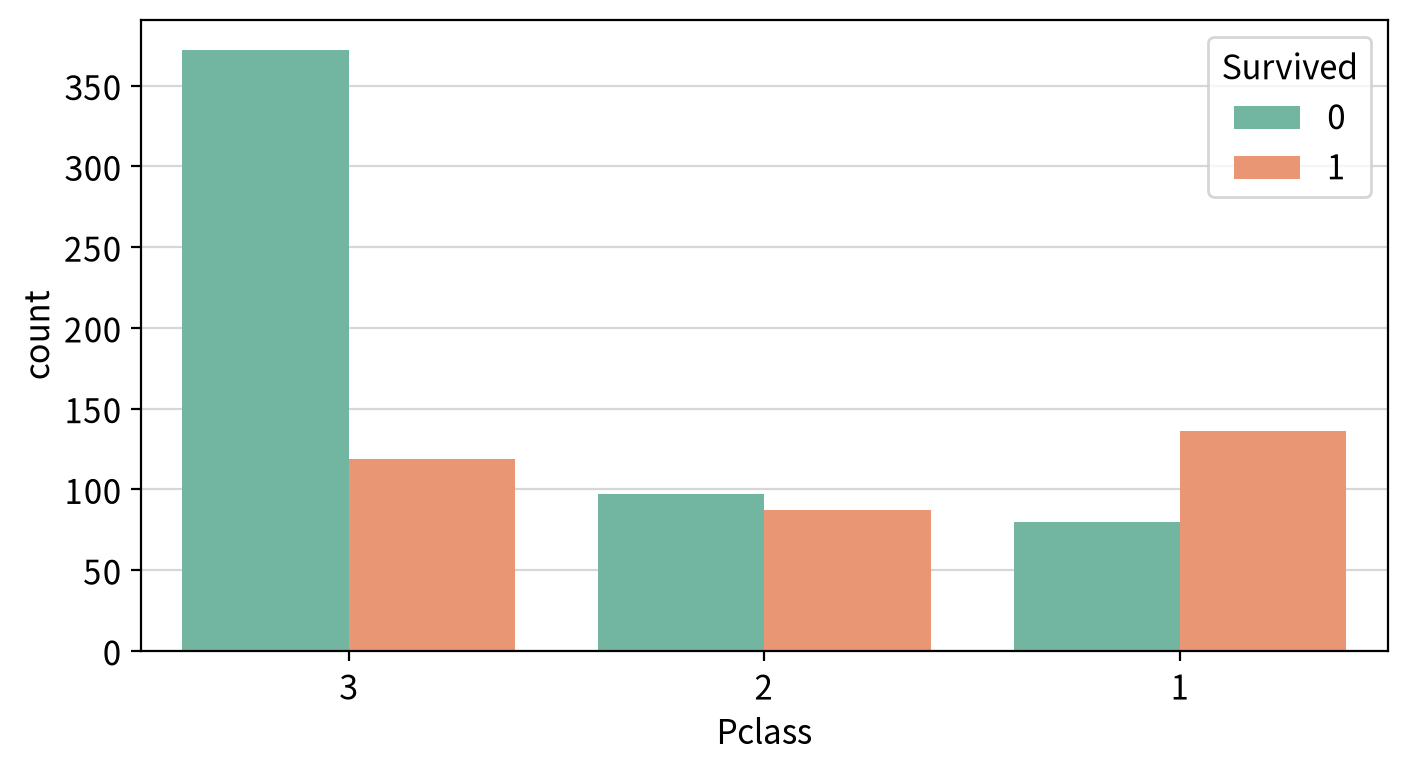

#### ▶︎ Sex(성별) → Survived

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Sex,Survived,Chi-square test of independence,260.717,1,0.0,True,0.5409,Strong,120.53,True


Survived,0,1
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


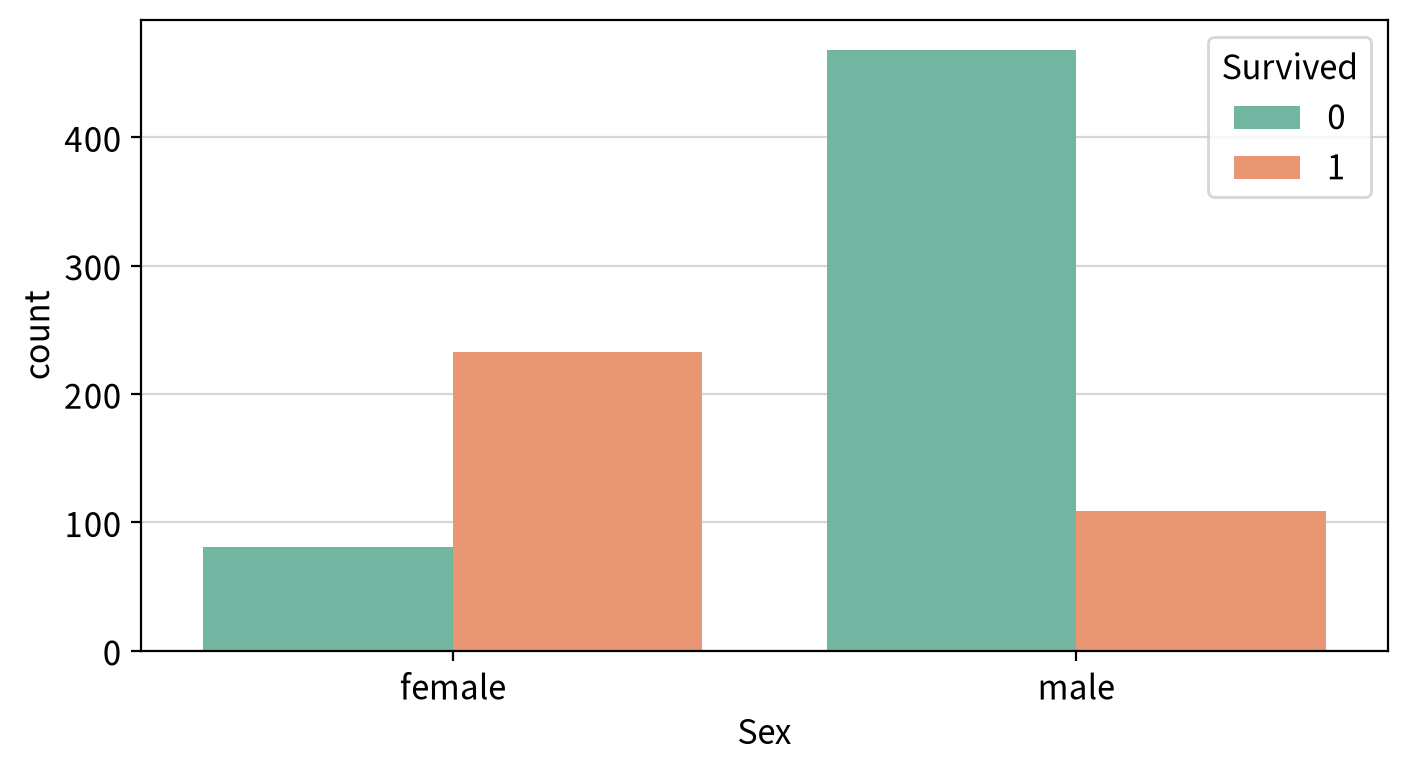

#### ▶︎ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)) → Survived

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Embarked,Survived,Chi-square test of independence,25.9645,2,0.000002,True,0.1707,Weak,29.56,True


Survived,0,1
Embarked,,
C,0.446429,0.553571
Q,0.610390,0.389610
S,0.660991,0.339009


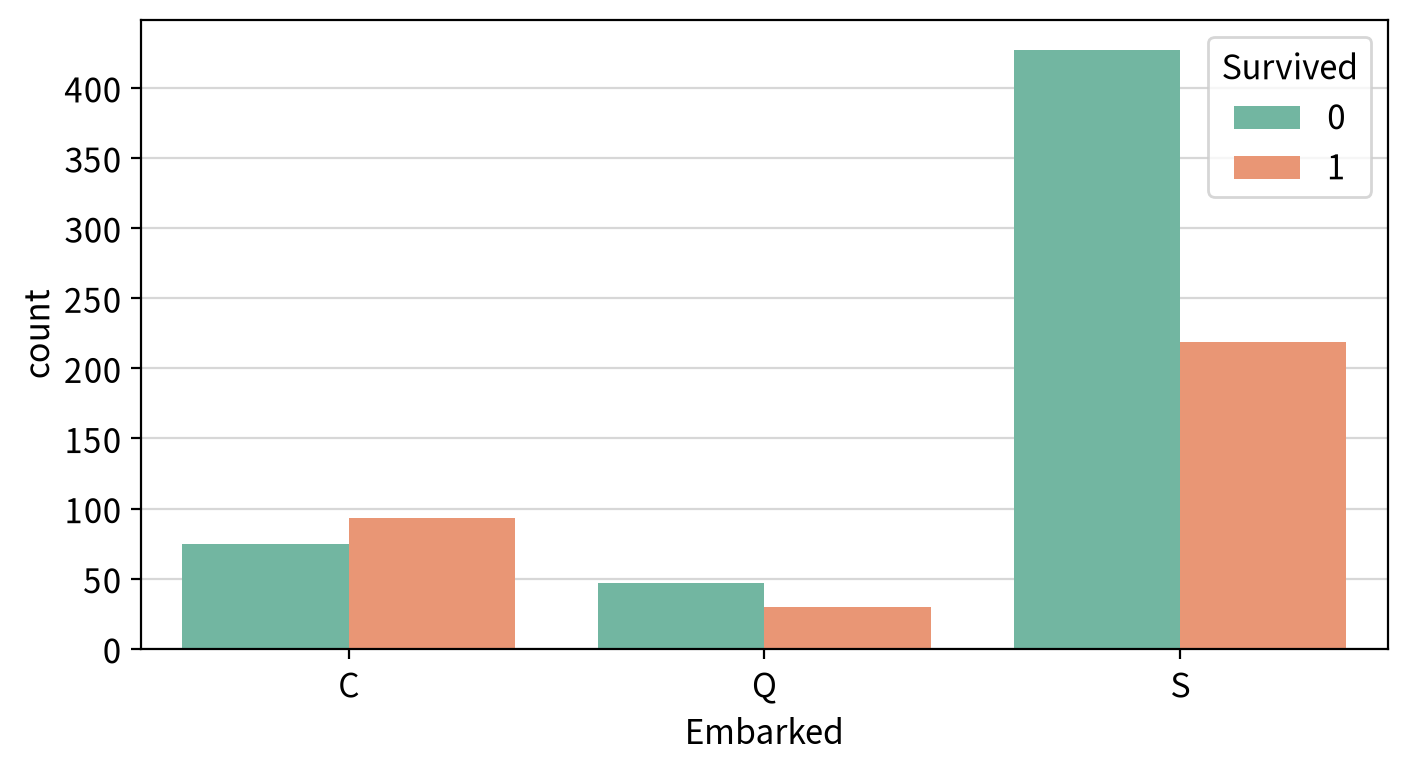

#### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) → Survived

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Title,Survived,Chi-square test of independence,291.3431,4,0.0,True,0.5718,Strong,6.91,True


Survived,0,1
Title,,
Mr,0.842308,0.157692
Officer,0.722222,0.277778
Master,0.425000,0.575000
Miss,0.297297,0.702703
Mrs,0.203125,0.796875


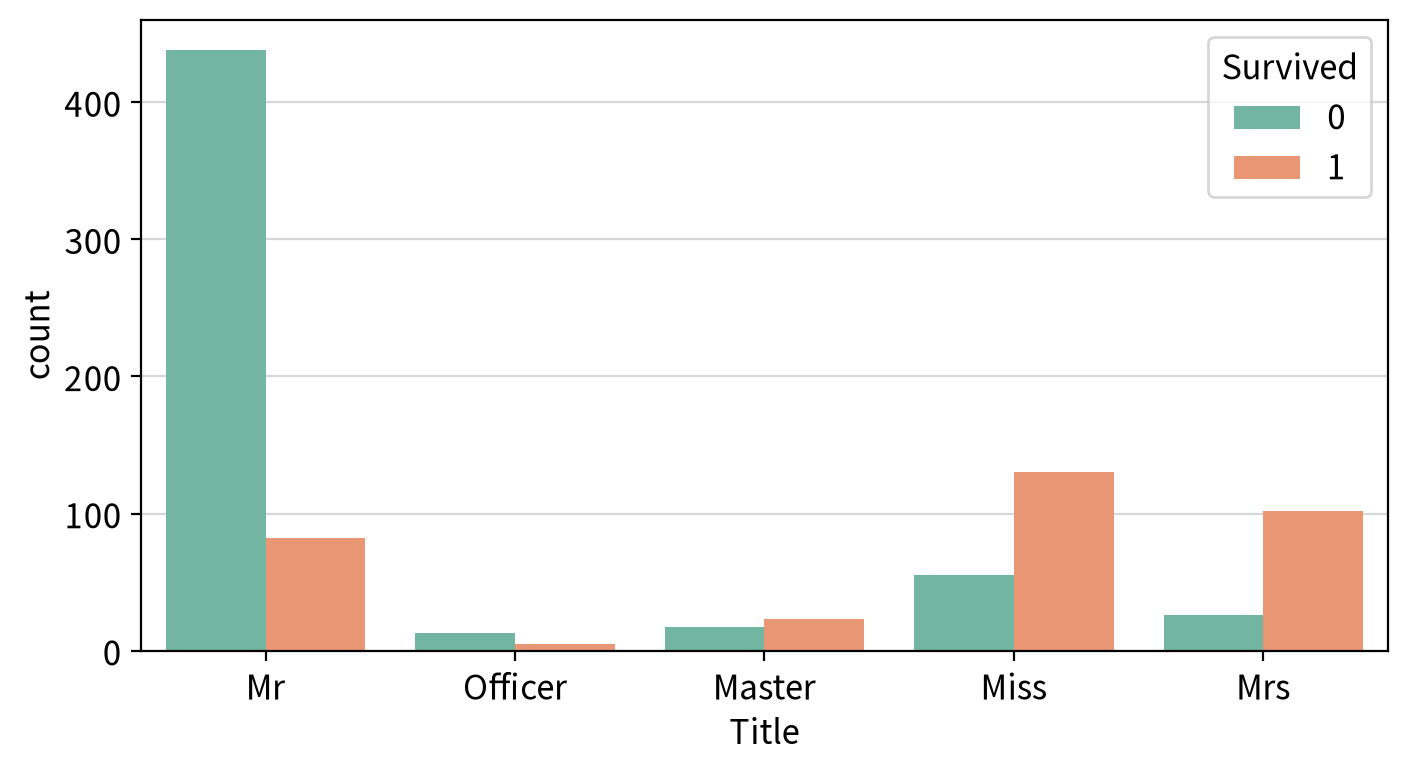

In [23]:
for n in nominal_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # 교차분석 (카이제곱 독립성 검정)
    display(my_stats.chi2_independence(df, x=n, y=target, plot=False))

    # 범주별 생존율 표
    rate = df.groupby(n, observed=True)[target].value_counts(normalize=True).unstack()
    display(rate)

    # 시각화: 범주별 생존 비율
    my_plot.countplot(data=df, x=n, hue=target, palette="Set2", width=720, height=400)

#### 💡 인사이트

| 변수 | χ² | 자유도 | 유의확률 | Cramer's V | 효과 크기 | 최소 기대빈도 | 채택 |
|---|---|---|---|---|---|---|---|
| **`Title`** | **291.34** | 4 | < 0.001 | **0.572** | **Strong** | 6.91 | ✅ |
| `Sex` | 260.72 | 1 | < 0.001 | 0.541 | **Strong** | 120.53 | ✅ |
| `Pclass` | 102.89 | 2 | < 0.001 | 0.340 | Moderate | 70.63 | ✅ |
| `Embarked` | 25.96 | 2 | < 0.001 | 0.171 | Weak | 29.56 | ✅ |

- 네 변수 모두 **최소 기대빈도가 5 이상**이라 카이제곱 검정의 가정을 충족한다. (`Title`의 6.91은 `Officer` 18명 때문에 가장 낮다)

**범주별 생존율**

| 변수 | 범주별 생존율 |
|---|---|
| **`Title`** | **Mrs 79.7% · Miss 70.3% · Master 57.5% · Officer 27.8% · Mr 15.8%** |
| `Sex` | 여성 **74.2%** vs 남성 **18.9%** — 3.9배 차이 |
| `Pclass` | 1등급 63.0% · 2등급 47.3% · 3등급 24.2% — 등급이 낮아질수록 단조 감소 |
| `Embarked` | C 55.4% · Q 39.0% · S 33.9% |

- **`Title`이 `Sex`를 앞선다.** χ² 291.34 > 260.72, V 0.572 > 0.541.
  자유도를 4개나 쓰고도 이긴 것이므로 **정보량이 실제로 더 많다**는 뜻이다.
- **차이가 나온 자리는 명확하다. `Master`(남자아이) 57.5%다.**
  - `Sex`는 이 40명을 성인 남성과 똑같은 `male`로 묶었다. 그 집단의 생존율은 18.9%다.
  - `Title`은 이들을 따로 떼어 **57.5%(약 3배)** 를 보여준다. 성인 남성(`Mr`) 15.8%와 비교하면 **3.6배**다.
    **"여성과 어린이 먼저"의 "어린이" 부분이 여기서 처음 드러난다.**
- **`Mrs`(79.7%)와 `Miss`(70.3%)도 갈린다.** `Sex`로는 둘 다 74.2%의 `female`이었다.
  기혼 여성이 미혼 여성보다 생존율이 **9.4%p 높다.** 아이를 동반한 어머니가 우선 구조된 정황이다.
- **`Officer`(27.8%)는 `Mr`(15.8%)보다 높지만 표본이 18명뿐**이다. 해석에 신중해야 한다.
- **`Pclass`는 등급마다 생존율이 약 20%p씩 떨어진다.** 1등급(63.0%)은 3등급(24.2%)의 **2.6배**다. 가설 H2의 방향과 정확히 일치한다.
- **`Embarked`의 차이는 항구 자체의 효과가 아닐 가능성이 크다.** Cherbourg(C)에서 탄 승객은 1등급 비중이 높다. (#9-2에서 확인)
- ⚠️ **`Title`과 `Sex`가 서로 얼마나 겹치는지는 따로 확인해야 한다.**
  #4-5의 교차표에서 `Mr`·`Master`는 전원 남성, `Miss`·`Mrs`는 전원 여성이었다.
  두 변수를 **함께 쓸 수 있는지는 #9-2에서 정량적으로 판정한다.**
- ⚠️ **효과 크기가 Weak라고 해서 버리면 안 된다.** 변수 채택은 **다른 변수를 통제한 모형**에서 최종 판정한다.

### 8-4. 가설 검증용 보조 집계 (H3 · H4)

- H3(가족 동반)과 H4(어린이)는 가설에서 정의한 집단이 **아직 변수로 존재하지 않는다.** 임시로 집단을 나눠 교차분석한다.
  - **H3:** `FamilySize` = 1 이면 단독, 2 이상이면 가족 동반
  - **H4:** 나이 12세 이하이면 어린이. ⚠️ 중앙값 대체가 결과를 흐리지 않도록 **결측을 채우기 전인 `origin`(714명)** 기준으로 본다.

In [24]:
# ── H3 : 가족 동반 여부별 생존율
h3 = DataFrame({
    "동반여부": np.where(df["FamilySize"] == 1, "단독", "가족동반"),
    target: df[target].astype(int),
})
display(Markdown("#### ▶︎ H3. 가족 동반 여부 → Survived"))
display(my_stats.chi2_independence(h3, x="동반여부", y=target, plot=False))
display(h3.groupby("동반여부")[target].agg(["count", "mean"])
          .rename(columns={"count": "인원수", "mean": "생존율"}).T)

# ── H4 : 어린이(12세 이하) 여부별 생존율 — 결측 대체 전 origin 기준
h4 = origin[["Age", target]].dropna().copy()
h4["어린이여부"] = np.where(h4["Age"] <= 12, "어린이(12세 이하)", "13세 이상")
display(Markdown("#### ▶︎ H4. 어린이 여부 → Survived (결측 대체 전 714명)"))
display(my_stats.chi2_independence(h4, x="어린이여부", y=target, plot=False))
display(h4.groupby("어린이여부")[target].agg(["count", "mean"])
          .rename(columns={"count": "인원수", "mean": "생존율"}).T)

# ── 참고 : 연령대별 생존율의 모양
h4["연령대"] = pd.cut(h4["Age"], bins=[0, 12, 19, 39, 59, 80],
                      labels=["0-12", "13-19", "20-39", "40-59", "60+"])
display(Markdown("#### ▶︎ 참고. 연령대별 생존율"))
display(h4.groupby("연령대", observed=True)[target].agg(["count", "mean"])
          .rename(columns={"count": "인원수", "mean": "생존율"}).T)

#### ▶︎ H3. 가족 동반 여부 → Survived

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
동반여부,Survived,Chi-square test of independence,36.0005,1,0.0,True,0.201,Weak,135.88,True


동반여부,가족동반,단독
인원수,354.00000,537.000000
생존율,0.50565,0.303538


#### ▶︎ H4. 어린이 여부 → Survived (결측 대체 전 714명)

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
어린이여부,Survived,Chi-square test of independence,8.7581,1,0.003082,True,0.1108,Weak,28.03,True


어린이여부,13세 이상,어린이(12세 이하)
인원수,645.000000,69.00000
생존율,0.387597,0.57971


#### ▶︎ 참고. 연령대별 생존율

연령대,0-12,13-19,20-39,40-59,60+
인원수,69.00000,95.000000,387.000000,137.000000,26.000000
생존율,0.57971,0.410526,0.387597,0.394161,0.269231


#### 💡 인사이트

| 가설 | 비교 집단 | 생존율 | χ² (p) | Cramer's V |
|---|---|---|---|---|
| **H3** | 가족 동반 354명 vs 단독 537명 | **50.6%** vs 30.4% | 36.00 (< 0.001) | 0.201 |
| **H4** | 어린이 69명 vs 13세 이상 645명 | **58.0%** vs 38.8% | 8.76 (0.003) | 0.111 |

- **H3: 가족과 동반한 승객의 생존율이 단독 승객보다 20.2%p 높다.** 방향은 가설과 일치한다.
  - 다만 #8-2에서 본 것처럼 **5명 이상 대가족은 오히려 단독 승객보다 생존율이 낮다.** "동반 여부"라는 이분법은 이 반전을 가린다.
  - → H3은 **"소규모(2~4명) 가족 동반 승객의 생존율이 가장 높다"** 로 다듬는 것이 데이터에 더 맞다.
- **H4: 12세 이하 어린이의 생존율이 13세 이상보다 19.2%p 높다.** 방향은 가설과 일치한다.
  - 연령대별로 보면 **0-12세 58.0% → 13-19세 41.1% → 20-39세 38.8% · 40-59세 39.4% → 60세 이상 26.9%** 다.
    어린이만 확연히 높고, 13~59세는 거의 평평하며, 60세 이상에서 다시 떨어진다.
  - #8-1에서 `Age`가 p = 0.270으로 "무관"하게 나온 이유가 이것이다. **나이와 생존의 관계는 직선이 아니라 양 끝에서만 꺾이는 모양**이고,
    전체 순위 비교는 이를 잡아내지 못한다.
  - → 모형에 `Age`를 연속형으로 그대로 넣기보다 **어린이 여부(구간화)** 로 넣는 편이 가설과 데이터 모양에 모두 맞는다.
    단 `Title`의 `Master`가 남자아이를 이미 담고 있으므로 **두 변수의 중복**을 함께 확인해야 한다.
- 두 가설 모두 효과 크기는 **Weak(V 0.11~0.20)** 로, `Sex`·`Title`(V 0.54~0.57)에 비하면 훨씬 약하다.

---
## #9. 다변량 분석

### 9-1. 연속형 독립변수 간 상관 분석

- 연속형 독립변수끼리는 종속변수가 명목형이어도 상관분석을 그대로 쓸 수 있다.
- **파생변수 `FamilySize`가 들어왔으므로 이번 점검은 특히 중요하다.**
  파생변수는 원본 컬럼으로 만든 것이라 **원재료와 겹칠 수밖에 없기 때문**이다.

In [25]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
display(my_stats.correlation_summary(corr))

# 분산팽창지수(VIF)로 한 번 더 확인
display(my_stats.compute_vif(df[continuous_cols]))

D:\helpers\my_stats.py:876: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_trim = pearsonr(trimmed[x], trimmed[y])[0]
D:\helpers\my_stats.py:876: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_trim = pearsonr(trimmed[x], trimmed[y])[0]
D:\helpers\my_stats.py:876: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_trim = pearsonr(trimmed[x], trimmed[y])[0]
D:\helpers\my_stats.py:876: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_trim = pearsonr(trimmed[x], trimmed[y])[0]


,Age,SibSp,Parch,Fare,FamilySize
Age,1.000,-0.145,-0.217,0.126,-0.183
SibSp,-0.145,1.000,0.450,0.447,0.849
Parch,-0.217,0.450,1.000,0.410,0.801
Fare,0.126,0.447,0.410,1.000,0.529
FamilySize,-0.183,0.849,0.801,0.529,1.000


,max-y,max-coef,count,columns
x,,,,
FamilySize,SibSp,0.8492,2,"SibSp, Parch"
SibSp,FamilySize,0.8492,1,FamilySize
Parch,FamilySize,0.8012,1,FamilySize
Fare,FamilySize,0.5289,0,-
Age,Parch,-0.2175,0,-


c:\Users\bhc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
c:\Users\bhc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,VIF
FamilySize,inf
Parch,inf
SibSp,inf
Age,1.092134
Fare,1.082121


#### 💡 인사이트

| 변수 | 가장 강하게 얽힌 상대 | 상관계수 | Strong 쌍 수 | VIF |
|---|---|---|---|---|
| `FamilySize` | `SibSp` | 0.849 | 2 (`SibSp`, `Parch`) | **∞** |
| `SibSp` | `FamilySize` | 0.849 | 1 | **∞** |
| `Parch` | `FamilySize` | 0.801 | 1 | **∞** |
| `Fare` | `FamilySize` | 0.529 | 0 | 1.08 |
| `Age` | `Parch` | −0.218 | 0 | 1.09 |

- **`FamilySize`·`SibSp`·`Parch` 세 변수의 VIF가 모두 무한대(∞)다.**
  `FamilySize = SibSp + Parch + 1`이라는 **완전한 선형 관계**가 있으므로 셋 중 하나는 나머지 둘로 정확히 계산된다.
  이 상태로는 회귀계수를 추정할 수 없다. → **원재료 2개를 빼고 `FamilySize` 하나만 남긴다.**
  - 출력의 `ConstantInputWarning` 경고는 `Parch`처럼 대부분이 0인 변수에서 절사 상관을 계산할 때 값이 상수가 되어 생긴 것으로, 결과 해석에는 영향이 없다.
- **`Fare`와 `Age`는 다른 연속형 변수와 중복이 없다.** VIF가 1.08, 1.09로 기준(10)에 한참 못 미친다.
- **`Fare`–`FamilySize`의 상관(0.529)은 단체 티켓 때문이다.** 요금이 1인이 아니라 티켓 단위 총액으로 기록되어, 가족이 많을수록 요금이 커진다.
- **`Age`–`Parch`의 음의 상관(−0.218)** 은 부모와 함께 탄 아이들이 `Parch`를 끌어올리기 때문이다. 약한 수준이라 문제 되지 않는다.
- ⚠️ 이 점검은 **연속형끼리만** 본 것이다. `Fare`와 `Pclass`(명목형)의 중복은 여기서 잡히지 않으므로, 모형에 함께 넣은 뒤 VIF로 다시 확인해야 한다.

### 9-2. 명목형 독립변수 간 연관성

- 명목형 변수끼리의 중복은 상관계수로 볼 수 없으므로, **카이제곱 독립성 검정의 Cramer's V** 로 확인한다.
- 앞에서 의심한 세 쌍을 점검한다.
  - `Title` ↔ `Sex` : 호칭이 성별을 세분화한 것인지 (#4-5, #8-3)
  - `Pclass` ↔ `Embarked` : 항구의 생존율 차이가 객실 등급 때문인지 (#8-3)
  - `Pclass` ↔ `Sex` : 두 핵심 변수가 서로 독립적인지

In [26]:
# ── 명목형 독립변수 쌍의 연관성 (Cramer's V)
for x, y in [("Title", "Sex"), ("Pclass", "Embarked"), ("Pclass", "Sex")]:
    display(Markdown(f"#### ▶︎ {x}({column_means[x]}) ↔ {y}({column_means[y]})"))
    display(my_stats.chi2_independence(df, x=x, y=y, plot=False))

# ── 탑승 항구별 객실 등급 구성비 (열 기준 비율)
display(Markdown("#### ▶︎ 탑승 항구별 객실 등급 구성비"))
display(crosstab(df["Pclass"], df["Embarked"], normalize="columns").round(3))

# ── 성별 × 객실 등급별 생존율
display(Markdown("#### ▶︎ 성별 × 객실 등급별 생존율"))
display(df.assign(_y=df[target].astype(int))
          .pivot_table(index="Sex", columns="Pclass", values="_y", aggfunc="mean", observed=True)
          .round(3))

#### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) ↔ Sex(성별)

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Title,Sex,Chi-square test of independence,886.8617,4,0.0,True,0.9977,Strong,6.34,True


#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) ↔ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton))

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Pclass,Embarked,Chi-square test of independence,122.6412,4,0.0,True,0.2623,Weak,15.9,True


#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) ↔ Sex(성별)

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Pclass,Sex,Chi-square test of independence,16.9715,2,0.000206,True,0.138,Weak,64.84,True


#### ▶︎ 탑승 항구별 객실 등급 구성비

Embarked,C,Q,S
Pclass,,,
3,0.393,0.935,0.546
2,0.101,0.039,0.254
1,0.506,0.026,0.200


#### ▶︎ 성별 × 객실 등급별 생존율

Pclass,3,2,1
Sex,,,
female,0.500,0.921,0.968
male,0.135,0.157,0.369


#### 💡 인사이트

| 변수 쌍 | Cramer's V | 효과 크기 | 판단 |
|---|---|---|---|
| **`Title` ↔ `Sex`** | **0.998** | **Strong** | **사실상 같은 정보** → 둘 중 하나만 투입 |
| `Pclass` ↔ `Embarked` | 0.262 | Weak | 항구 효과에 객실 등급이 섞여 있음 |
| `Pclass` ↔ `Sex` | 0.138 | Weak | 함께 투입 가능 |

- **`Title`과 `Sex`의 V = 0.998은 완전한 중복(1.0)에 거의 닿은 값이다.** 두 변수를 함께 넣으면 계수가 불안정해지고 해석이 불가능해진다.
  - **`Title`을 남긴다.** `Sex`의 정보를 거의 그대로 담으면서, `Sex`가 놓친 **`Master`(남자아이)와 `Mrs`/`Miss`의 차이**까지 담기 때문이다(#8-3에서 χ²·V 모두 우위).
- **`Embarked`의 생존율 차이는 상당 부분 객실 등급 때문이다.**
  - Cherbourg(C) 승객의 **50.6%가 1등급**인 반면, Southampton(S)은 20.0%, Queenstown(Q)은 **2.6%** 뿐이다. Q 승객의 93.5%는 3등급이다.
  - 그런데 Q(39.0%)의 생존율은 S(33.9%)보다 높다. 3등급이 압도적인데도 그렇다는 점에서 **항구 고유의 차이가 일부 남아 있을 수도 있다.**
  - → `Embarked`는 **보류**하고, `Pclass`를 통제한 모형에서 계수로 판정한다.
- **성별과 등급은 서로 독립적이지만, 함께 작용한다.**

  | | 1등급 | 2등급 | 3등급 |
  |---|---|---|---|
  | 여성 | **96.8%** | 92.1% | 50.0% |
  | 남성 | 36.9% | 15.7% | 13.5% |

  - 여성은 1·2등급이면 **거의 전원 생존**했지만 3등급에서는 **절반**으로 떨어진다.
  - 남성은 1등급만 36.9%로 높고, 2·3등급은 거의 차이가 없다(15.7% vs 13.5%).
  - 즉 **등급의 효과가 성별에 따라 다르다(교호작용).** 주효과만 넣은 모형은 이 차이를 평균 내 버린다. → 모형 개선 단계에서 `Title × Pclass` 교호작용을 검토할 수 있다.

---
## #10. 최종 변수 선택

### 10-1. 변수별 판정

| 채택여부 | 변수 | 검정방법 | 유의확률 | 효과 크기 | 방향 | 공선성 신호 | 근거 |
|---|---|---|---|---|---|---|---|
| ✅ 채택 | **`Title`** | 교차분석 | < 0.001 | V = 0.572 (**Strong**) | Mrs > Miss > Master > Officer > Mr | **`Sex`와 V = 0.998** | 이 데이터 최고 설명력. `Sex` 정보 + 남자아이(`Master`) 정보 |
| ✅ 채택 | `Pclass` | 교차분석 | < 0.001 | V = 0.340 (Moderate) | 1등급 > 2등급 > 3등급 | `Sex`와 V = 0.138 (낮음) | 등급 순서대로 단조 감소. 가설 H2의 핵심 변수 |
| ✅ 채택 | **`FamilySize`** | Mann-Whitney U | < 0.001 | — | **역U자** (2~4명 최고) | VIF = ∞ (`SibSp`·`Parch`의 합) | 원재료 2개를 대표. **구간화 후 투입** 검토 |
| ✅ 채택 | `Fare` | Mann-Whitney U | < 0.001 | — | 생존 > 사망 (중앙값 26.0 vs 10.5) | VIF 1.08 (연속형 내) | 왜도 +4.79 → **`log1p` 후보**. `Pclass`와 함께 VIF 재확인 |
| 🟡 보류 | `Age` | Mann-Whitney U | 0.270 | — | 어린이만 높음 (58.0%) | VIF 1.09 | 단독 차이는 없으나 **비선형**. 어린이 구간화 후 `Title`(`Master`)과 중복 확인 |
| 🟡 보류 | `Embarked` | 교차분석 | < 0.001 | V = 0.171 (Weak) | C > Q > S | **`Pclass`와 V = 0.262** | C 승객의 50.6%가 1등급 → 교란 가능성. 모형에서 계수로 판정 |
| ❌ 제외 | `Sex` | 교차분석 | < 0.001 | V = 0.541 (Strong) | 여성 > 남성 | **`Title`과 V = 0.998** | 단독으로는 강하지만 **`Title`과 사실상 같은 정보** |
| ❌ 제외 | `SibSp` | Mann-Whitney U | 0.008 | — | 1~2명 동반 유리, 3명 이상 불리 | **VIF = ∞** | `FamilySize`에 포함됨 |
| ❌ 제외 | `Parch` | Mann-Whitney U | < 0.001 | — | 생존 > 사망 | **VIF = ∞** | `FamilySize`에 포함됨 |
| ❌ 제외 | `PassengerId` | — | — | — | — | — | 행마다 값이 다른 **식별자** (#3에서 제거) |
| ❌ 제외 | `Name` | — | — | — | — | — | 자유 텍스트 — **단, `Title`을 추출해 활용** (#4) |
| ❌ 제외 | `Ticket` | — | — | — | — | — | 문자열 식별자 (#3에서 제거) |
| ❌ 제외 | `Cabin` | — | — | — | — | — | **결측 77.1%** (#3에서 제거) |

- **단변량으로 유의했던 9개 중 3개(`Sex`, `SibSp`, `Parch`)를 중복 때문에 뺐다.** 유의한 변수라도 **다른 변수가 같은 정보를 이미 담고 있으면** 모형에 넣을 이유가 없다.
- **보류한 2개(`Age`, `Embarked`)는 버린 것이 아니다.** 단변량 결과와 다른 변수의 영향이 얽혀 있어, **다른 변수를 통제한 모형의 계수**로 최종 판정한다.

### 10-2. 가설 잠정 판정

> EDA 단계의 판정이다. 다른 변수를 통제한 **로지스틱 회귀 계수(오즈비)** 로 최종 확정한다.

| 가설 | EDA 근거 | 잠정 판정 |
|---|---|---|
| **H1.** 남성 승객의 생존율은 여성 승객보다 낮을 것이다. | 남성 18.9% vs 여성 74.2% (χ² = 260.72, p < 0.001, V = 0.541) | **지지** — 단, 모형에는 `Sex` 대신 `Title`로 투입 (`Mr` 기준) |
| **H2.** 상위 객실 등급일수록 생존율이 높을 것이다. | 1등급 63.0% > 2등급 47.3% > 3등급 24.2% (χ² = 102.89, p < 0.001, V = 0.340) | **지지** — 단조 감소가 뚜렷함 |
| **H3.** 가족과 동승한 승객의 생존율은 단독 승객보다 높을 것이다. | 동반 50.6% vs 단독 30.4% (χ² = 36.00, p < 0.001, V = 0.201) | **수정 후 지지** — 5명 이상 대가족은 오히려 낮음(역U자). **"2~4명 소가족"** 으로 범위를 좁힌다 |
| **H4.** 어린이(12세 이하) 승객의 생존율은 성인 승객보다 높을 것이다. | 어린이 58.0% vs 13세 이상 38.8% (χ² = 8.76, p = 0.003, V = 0.111) | **지지** — 단, 연속형 `Age`로는 드러나지 않음(p = 0.270). 구간화가 필요 |

### 10-3. 모델링 설계 근거

**투입 변수**

- **채택 4개:** `Title`, `Pclass`, `FamilySize`, `Fare`
- **보류 2개:** `Age`(어린이 구간화), `Embarked` → 채택 변수와 함께 넣은 뒤 유의성과 VIF로 판정
- **제외:** `Sex`(`Title`과 V = 0.998), `SibSp`·`Parch`(`FamilySize`와 VIF = ∞), 식별자·결측 과다 컬럼 4개

**더미 변수 기준 범주**

| 변수 | 기준 범주 | 계수 해석 |
|---|---|---|
| `Title` | `Mr` (성인 남성) | 성인 남성 대비 생존 오즈가 몇 배인가 |
| `Pclass` | 3등급 | 3등급 대비 2등급·1등급의 생존 오즈가 몇 배인가 |
| `Embarked` | `C` (알파벳 순 첫 범주) | Cherbourg 대비 Q·S의 생존 오즈 |

**변수 변환 필요성**

- `Fare` : 왜도 +4.79 → **`log1p`** (0원 15건이 있어 `log` 불가)
- `FamilySize` : 역U자 관계 → **구간화(단독 / 2~4명 / 5명 이상)** 또는 제곱항
- `Age` : 양 끝에서만 꺾이는 관계 → **어린이 여부(12세 이하)** 더미
- 로지스틱 회귀는 독립변수의 정규성을 가정하지 않으므로, 변환의 근거는 왜도가 아니라 **로짓과의 선형 관계**다. 변환 전후를 모형 성능으로 비교한다.

**평가지표 우선순위와 이유**

> **1순위 정확도(Accuracy), 2순위 AUC, 보조 재현율·정밀도.**
> Kaggle 대회의 공식 평가 지표가 정확도이므로 1순위로 둔다. 단 **바닥값 61.6%** (전원 사망 예측)와 반드시 비교한다.
> 정확도는 분류 기준값(0.5)에 따라 달라지므로, 기준값과 무관하게 순위 예측력을 보는 **AUC**를 함께 본다.
> 생존자(38.4%)가 소수 범주이므로, 생존자를 얼마나 놓치는지(**재현율**)도 보조 지표로 확인한다.
> 평가는 `train.csv` 891명을 **학습용과 검증용으로 나누거나 교차검증**으로 한다(`test.csv`에는 정답이 없음).

### 10-4. 이 장의 결론과 다음 단계

**핵심 인사이트**

1. **생존을 가른 1순위 요인은 성별이고, 호칭(`Title`)이 그것을 더 정교하게 담는다.** 성별(V = 0.541)보다 호칭(V = 0.572)의 설명력이 높은 이유는 **남자아이(`Master`, 57.5%)** 를 성인 남성(15.8%)과 분리했기 때문이다.
2. **객실 등급은 성별 다음으로 강한 요인이며, 성별과 함께 작용한다.** 1·2등급 여성은 90% 이상 생존했지만 3등급 여성은 50%에 그쳤다.
3. **가족은 '있으면 유리'가 아니라 '적당히 있으면 유리'하다.** 2~4명 가족의 생존율(55~72%)은 단독(30.4%)과 5명 이상 대가족(0~33%)보다 모두 높다.
4. **단변량 검정의 "무관"은 최종 판정이 아니다.** `Age`는 p = 0.270이었지만, 어린이(58.0%)와 60세 이상(26.9%)으로 나누면 차이가 뚜렷하다. 관계가 직선이 아니면 순위·평균 비교는 그것을 놓친다.
5. **유의한 변수라도 다른 변수가 같은 정보를 담고 있으면 뺀다.** `Sex`(V = 0.998 중복)와 `SibSp`·`Parch`(VIF = ∞)가 그 예다.

**다음에 시도할 것**

- **모델링:** 채택 4개 + 보류 2개로 로지스틱 회귀를 적합하고, 후진소거로 보류 변수를 판정한다.
- **결측 대체 개선:** `Age`를 전체 중앙값(28세) 대신 **`Title`별 중앙값**으로 다시 채워, 28세 인공 봉우리가 줄어드는지와 모형 성능이 달라지는지 비교한다.
- **교호작용:** `Title × Pclass`(또는 `Sex × Pclass`)를 추가해 "3등급 여성"의 낮은 생존율을 모형이 잡아내는지 확인한다.
- **평가:** 교차검증으로 정확도를 측정하고 바닥값 61.6%와 비교한다.

---

## 파일 저장하기 

In [27]:
import os, json

os.makedirs("titanic/data", exist_ok=True)

#10에서 제외하기로 한 변수를 뺀 모델링용 데이터셋 저장
df_model = df.drop(columns=["Sex", "SibSp", "Parch"])
df_model.to_pickle("titanic/data/titanic_df.pkl")

# 컬럼 의미 사전도 함께 저장 (SHAP 노트북에서 그래프 제목 등에 재사용)
with open("titanic/data/column_means.json", "w", encoding="utf-8") as f:
    json.dump(column_means, f, ensure_ascii=False, indent=2)